The source code can be found on https://github.com/luisiee/paa-tana-project.

In [1]:
%load_ext autoreload
%autoreload 2
import warnings

import astropy.units as u
import matplotlib.pyplot as plt

import src.halo_dynamics as a
import src.subhalo_statistics as b

warnings.filterwarnings('ignore')

plt.style.use("src/nicefigures.mplstyle")
OUTPUT = "figures"

## A: Dynamical Analysis of a DM Halo

In [4]:
data_path = "data/cutout_188106.hdf5"

### Spherical Potential

#### Potential & Density

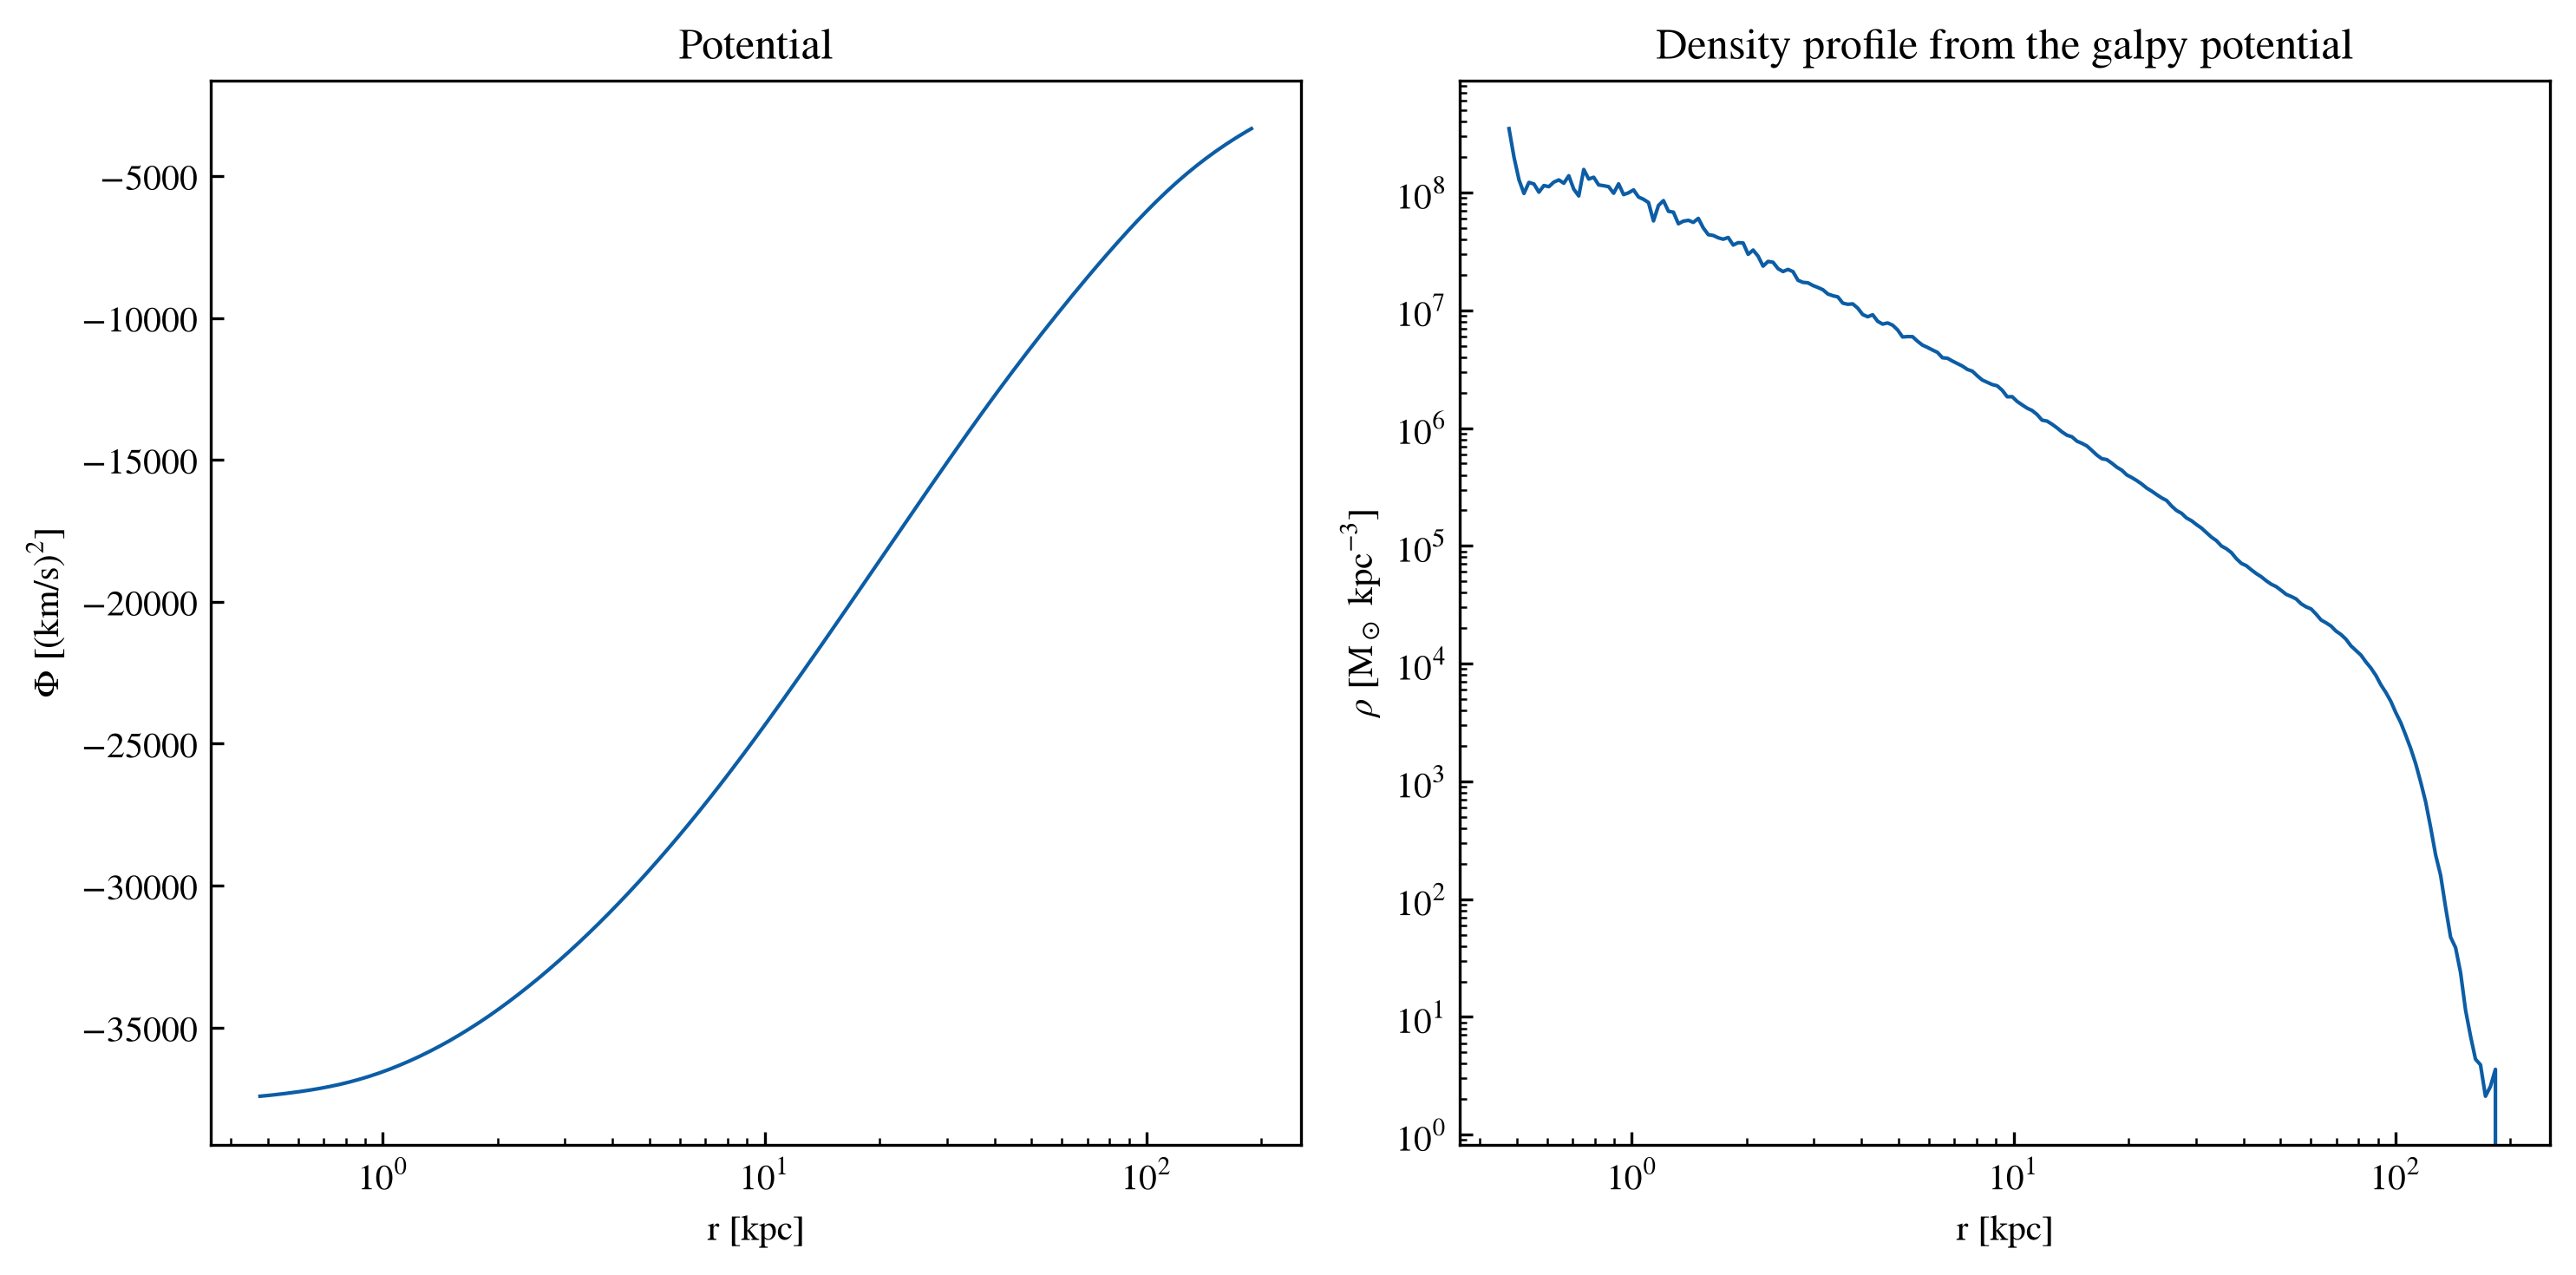

In [5]:
a.spherical_potential_plotter(data_path, plot=True, output=f"{OUTPUT}/halo_potential_density.png");

Above the potential and the density derived from the particle data (or derived from the galpy model built on the particle data) can be seen. The potential was built under the assumption of a spherically symmetric system/halo, the validity of this assumption is checked later. It can directly be noticed that the density on small length scales is much noisier than the center of the radius interval. This is due to the method by which it was built. The enclosed mass was constructed from inside out by adding more and more particles to the total mass in the center, at the small length scales this means every included particle can cause a big jump in the mass/density. To reduce this noise the first few radius bins are omitted from the data shown here. If this isn't done the fitting later on would be less reliable.

Now a number of spherically symmetric models can be fitted to the density curve, these are:

- Plummer model
- Einasto model
- Truncated NFW model
- Truncated Hernquist model

and are shown in the figure below. These four were chosen for different reasons: Einasto and NFW were chosen because they were mentioned in the course notes in the section on the density profile for DM halos, this seemed like a good start. Hernquist and Plummer were chosen because they were mentioned in the section specifically on spherical potentials. In the galpy documentation we found the truncated versions of NFW and Hernquist, this seemed like a better fit to a realistic simulation/data. The goodness of fit was tested by the rms deviation between the fitted model and the data, the Einasto model had the smallest rms value so it was chosen as the best model. This agrees with what we learned during the theory lectures.

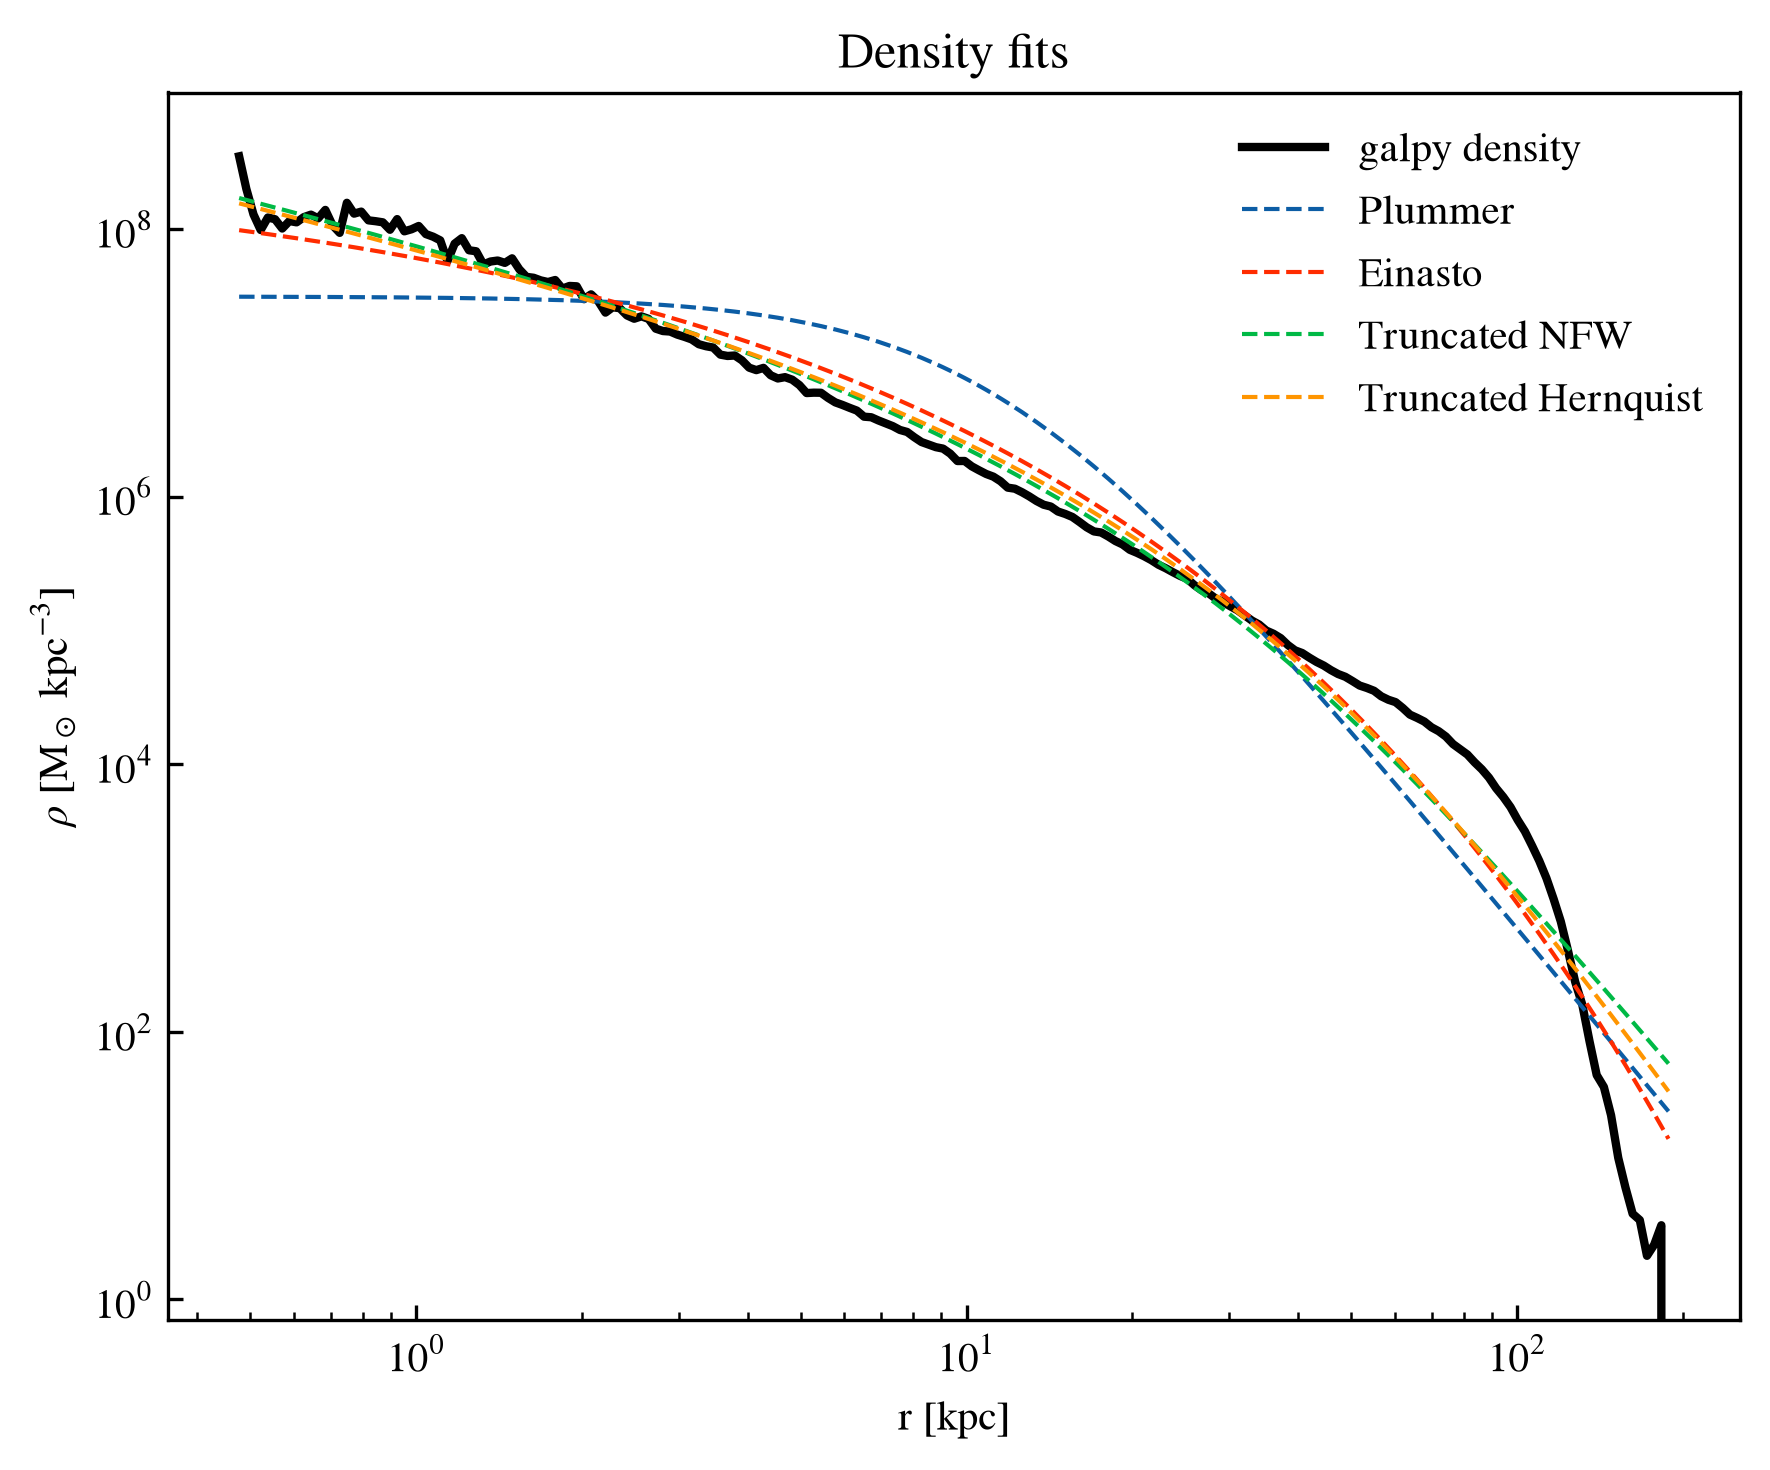

In [6]:
a.data_fitter(data_path, plot=True, output=f"{OUTPUT}/halo_density_fit.png");

#### Orbits

Here the typical rosette orbits of a spherically symmetric potential can be seen, this is exactly what's expected if spherical symmetry is assumed.

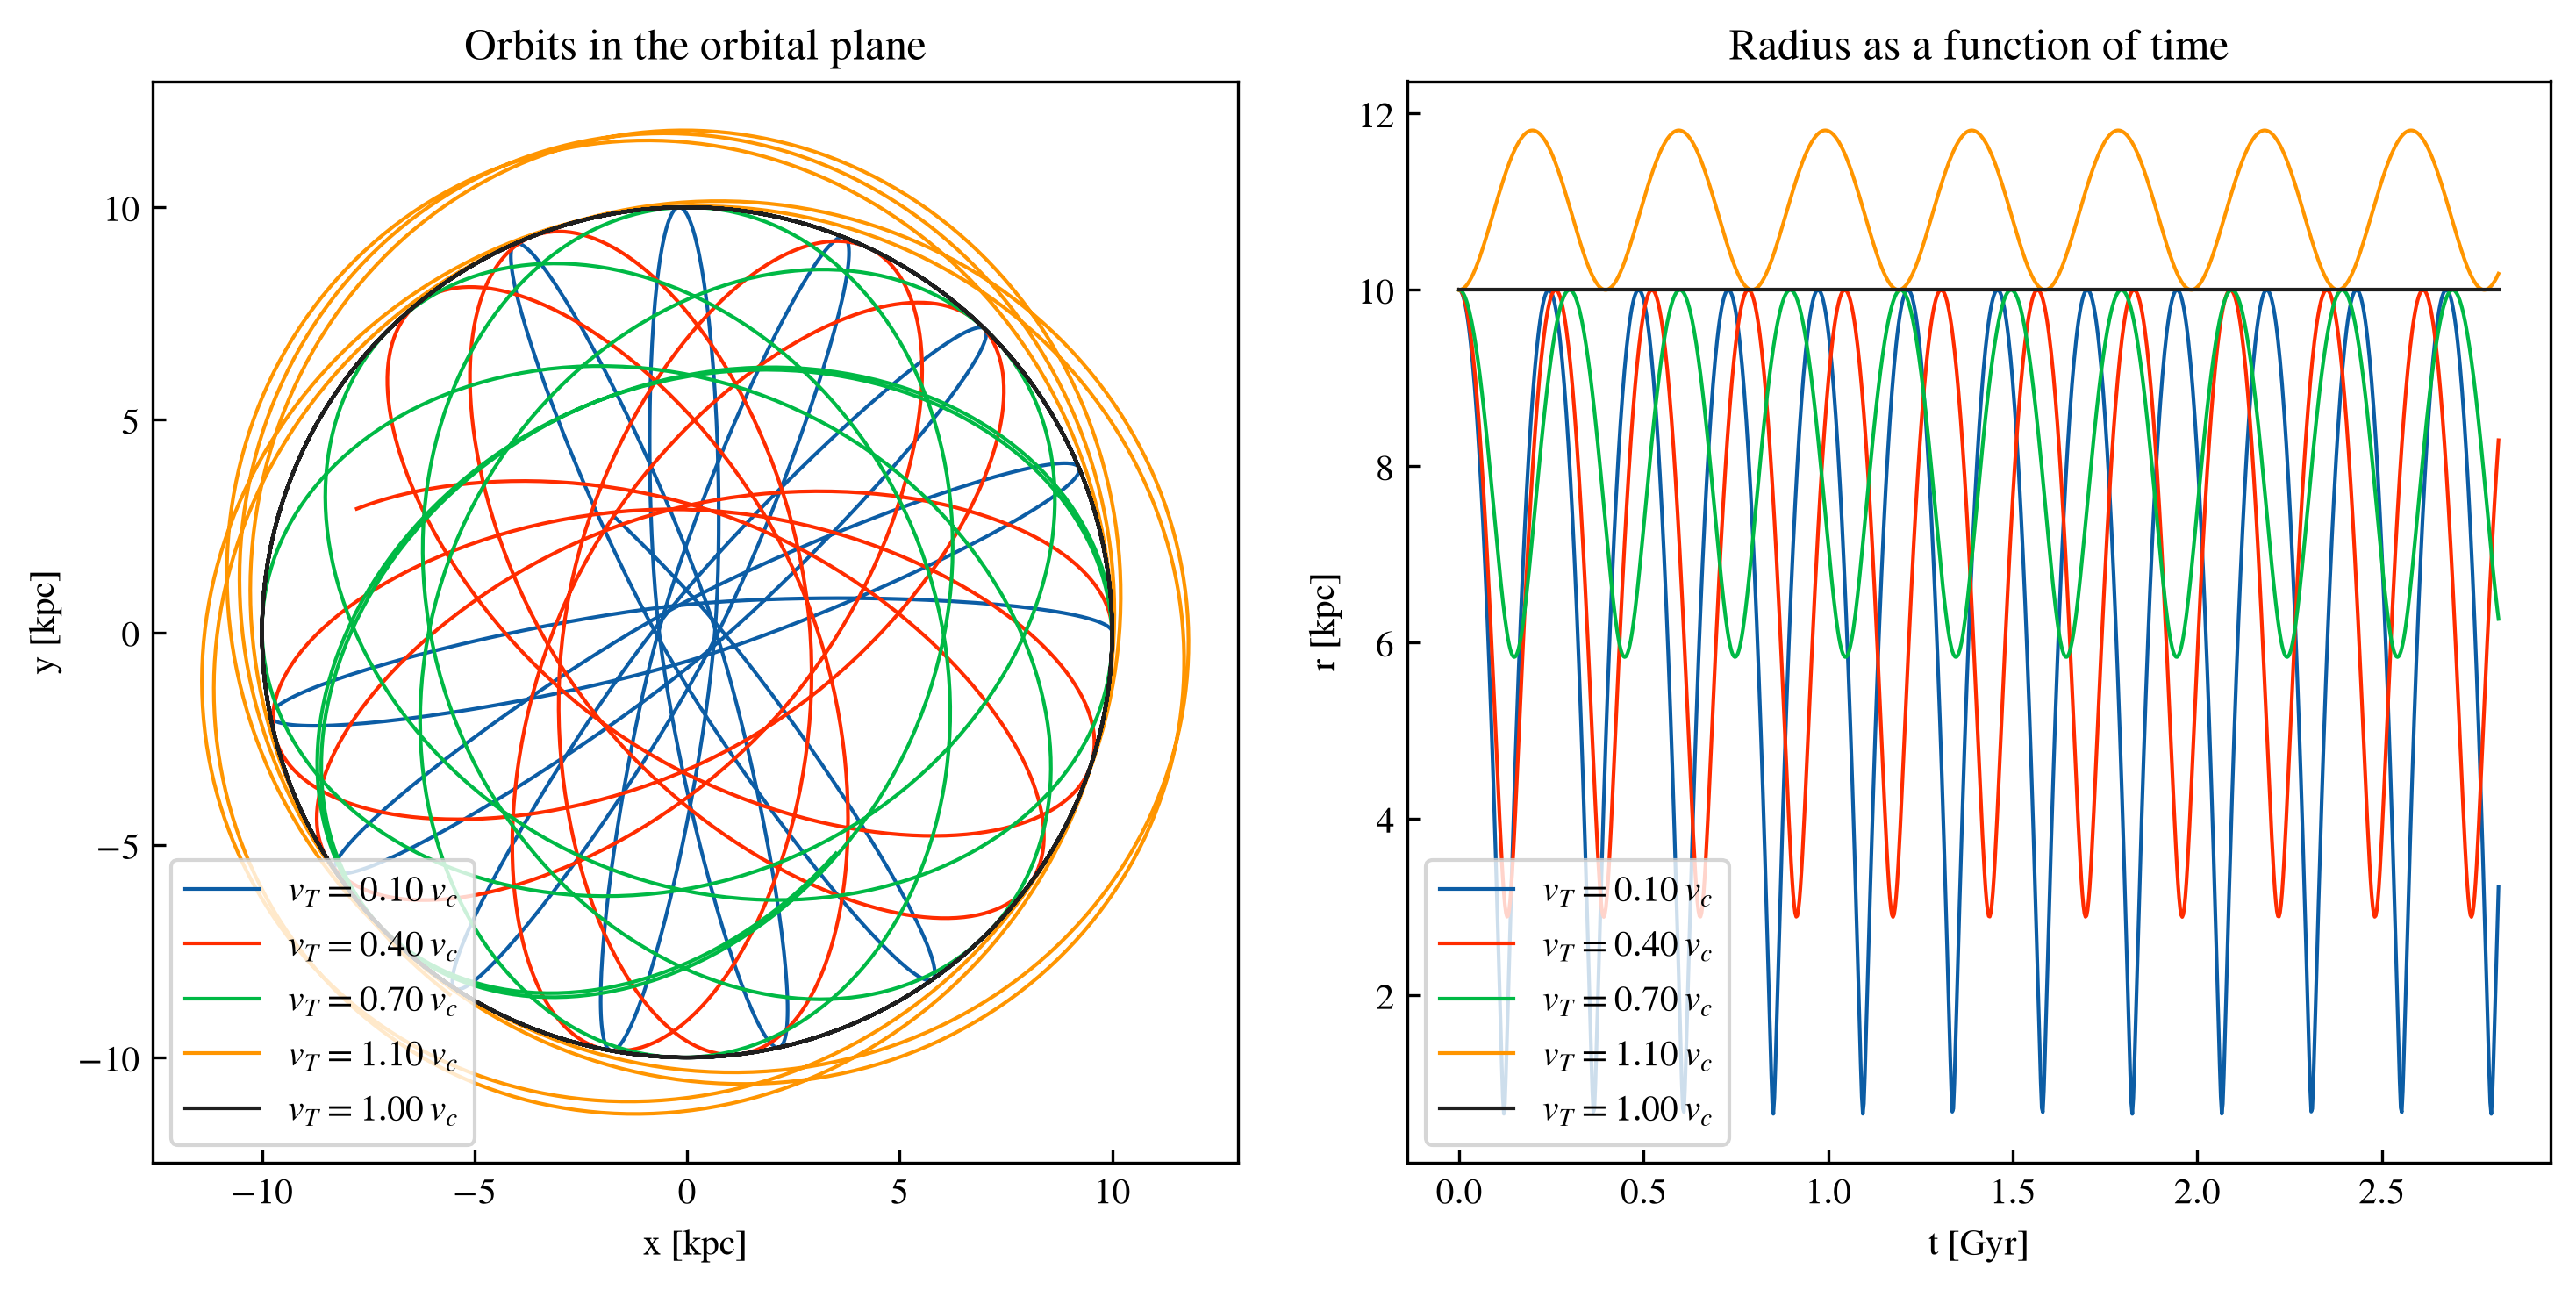

In [7]:
pot_einasto, rho_einasto, r = a.build_Einasto(data_path)
a.integrate_orbits(pot_einasto, r0=10 * u.kpc, f_vc=(0.1, 0.4, 0.7, 1.1, 1.0), plot=True, output=f"{OUTPUT}/dm_orbits_einasto.png");

#### Dynamical Analysis

In the figure below, the velocity dispersion in the radial and tangential direction can be seen. They were extracted directly from the particle data and not the fitted Einasto model. Again due to noise concerns the start of the graph was omitted from the data. Near the largest length scales there is also a *very* noticeable random jump in the data, this is because at these large distances there's very little data in each radius/distance bin. Note that because the dispersions were calculated directly from the data this graph doesn't suffer from the assumption of spherical symmetry.

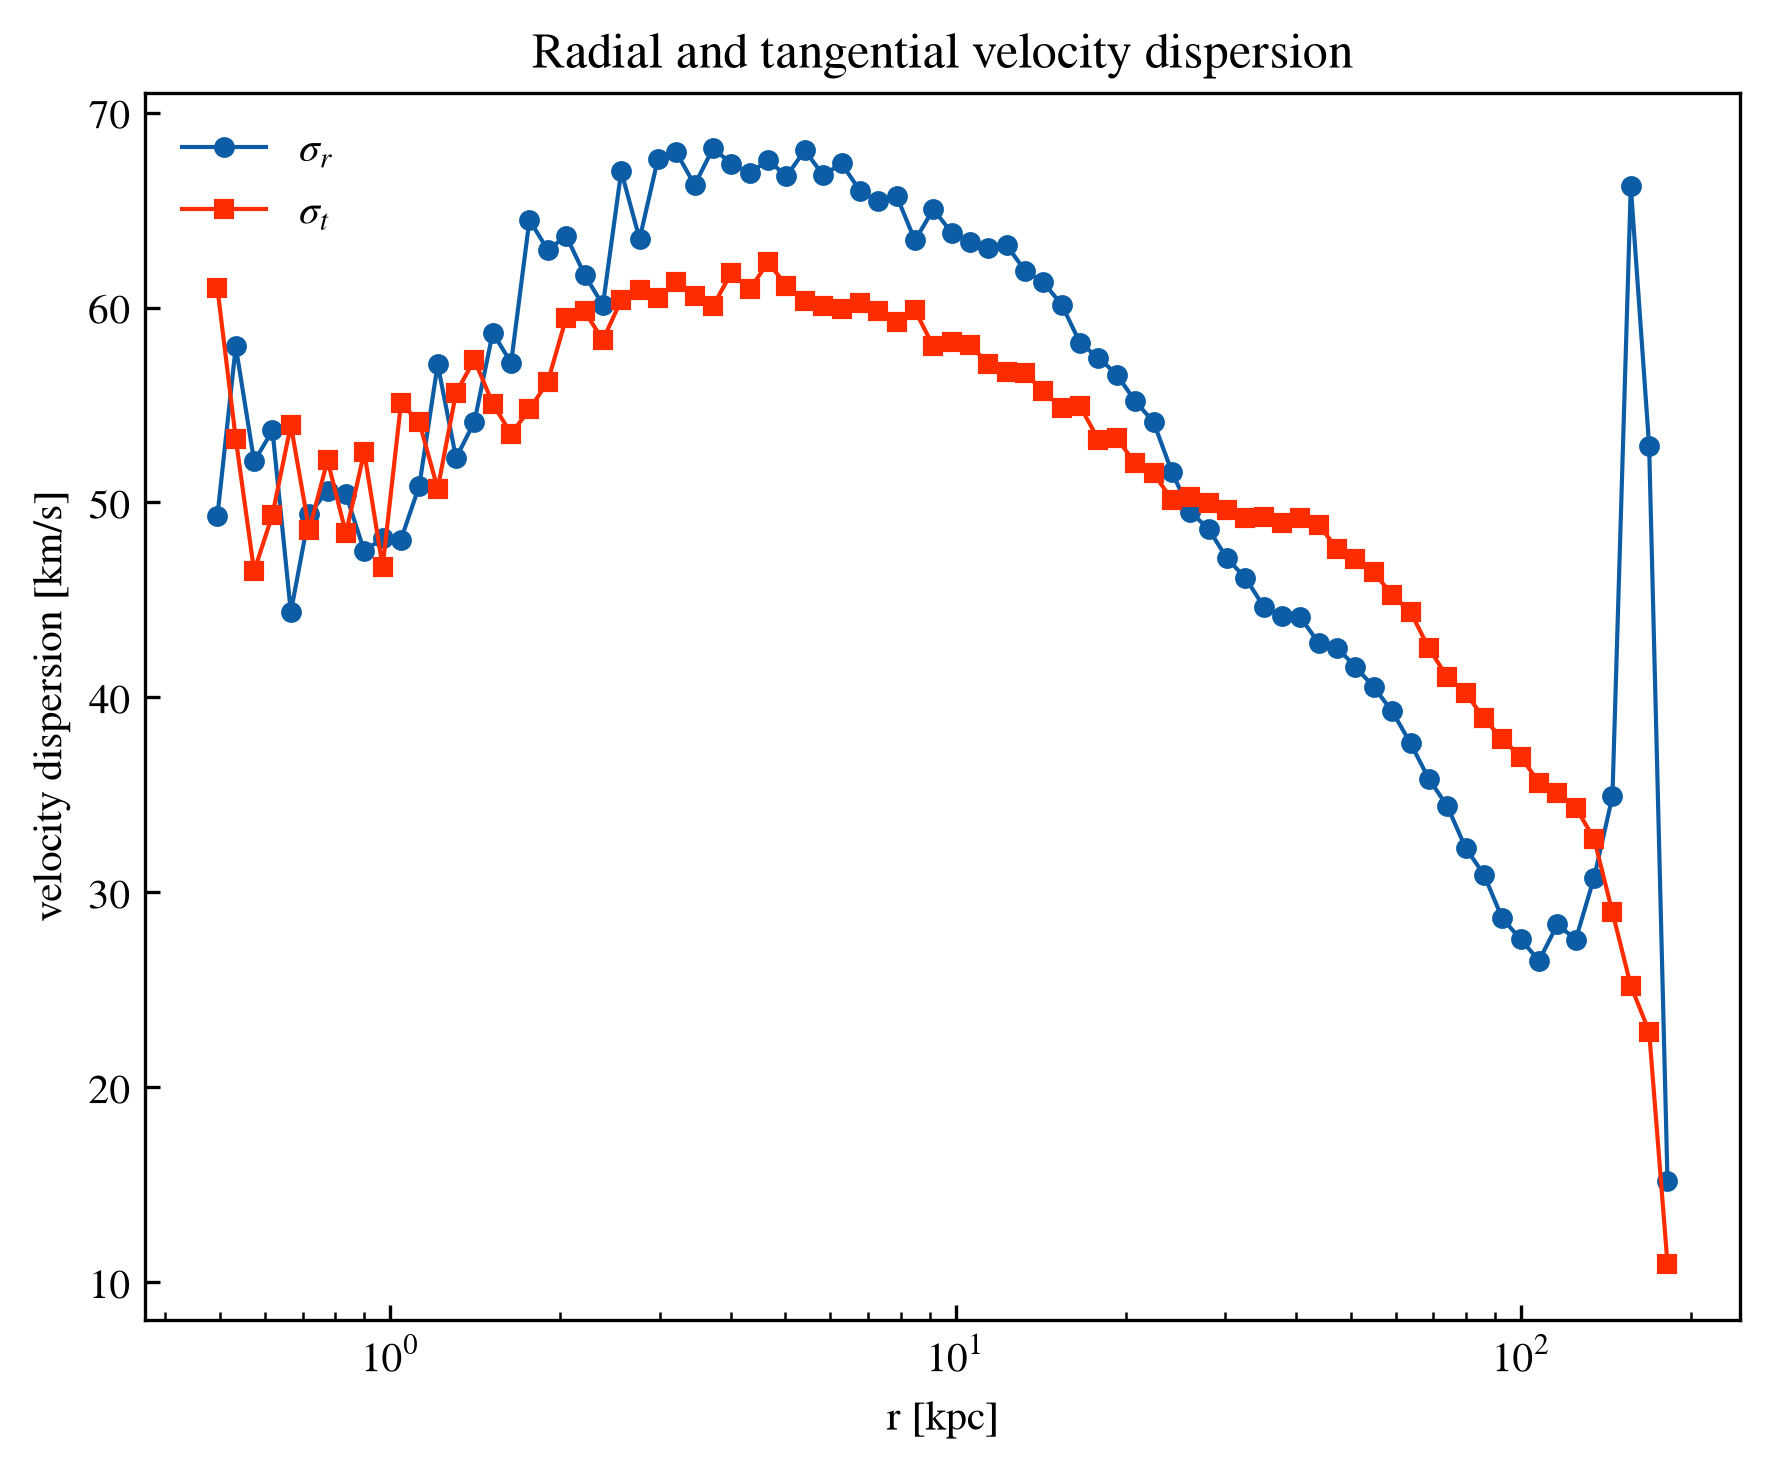

In [6]:
a.velocity_dispersions(data_path, n_bins=80, plot=True, output=f"{OUTPUT}/dm_dispersions.png");

We also plot the rotation curve computed by three different methods:

- From the Einasto model: galpy function `vcirc`
- From the particle data: enclosed mass
- From the particle data: tangential velocity

It can directly be seen that there is a big discrepancy between all curves. The big difference between the fit and the enclosed mass is most likely due to the inaccuracy of the assumption of spherical symmetry. The fact that the tangential velocity of the actual particles is very different from the other data is because the orbits of DM particles are not circular: they have a varying radial component.

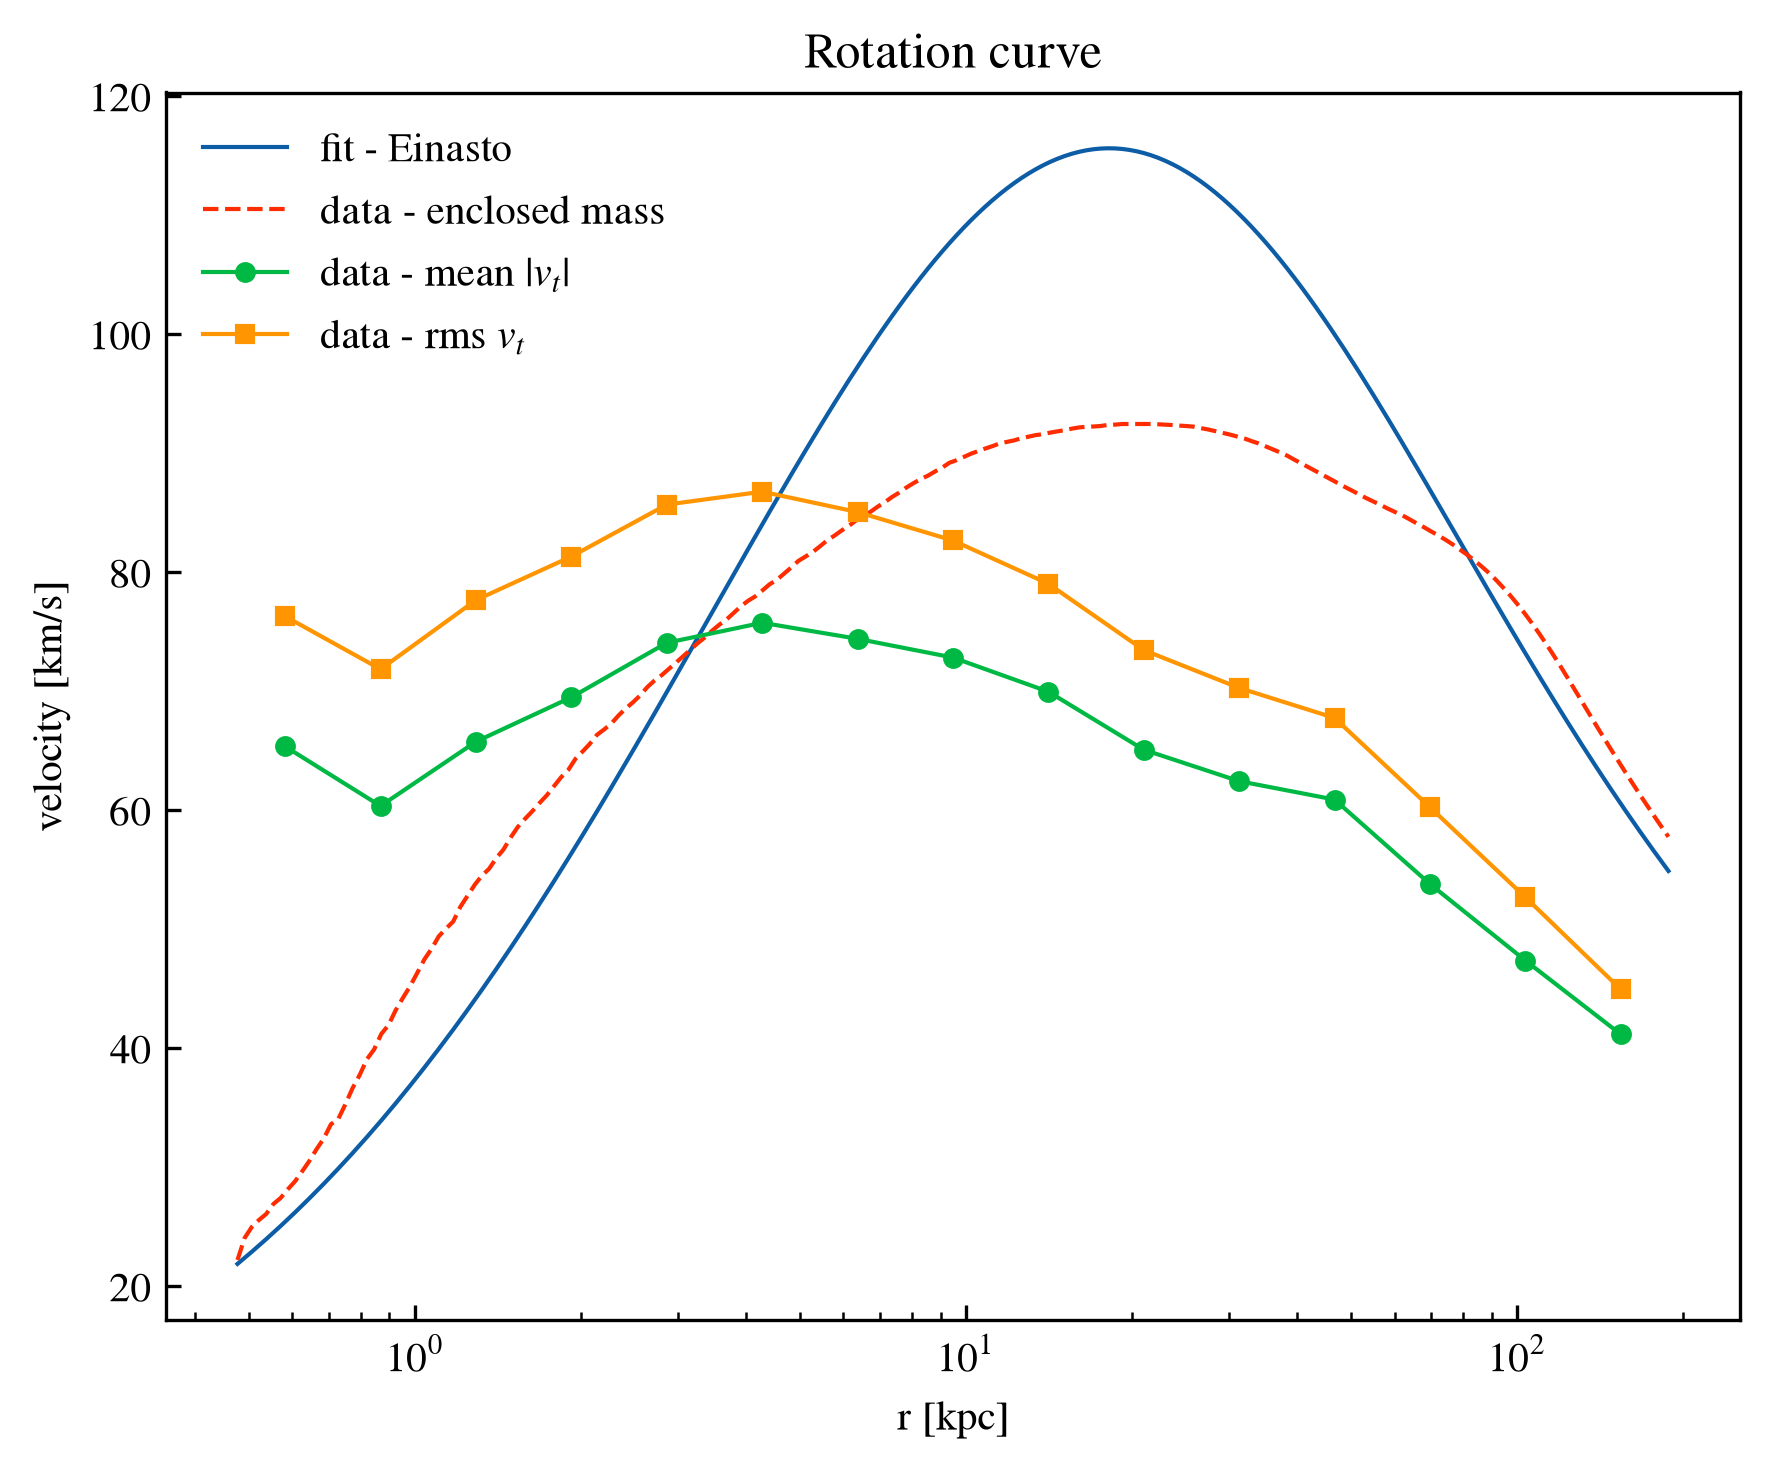

In [7]:
a.compare_rotation_curves(data_path, plot=True, output=f"{OUTPUT}/dm_circular_velocities.png");

### Asymmetric Potential

#### Potential & Density

We now review the assumption of spherical symmetry.

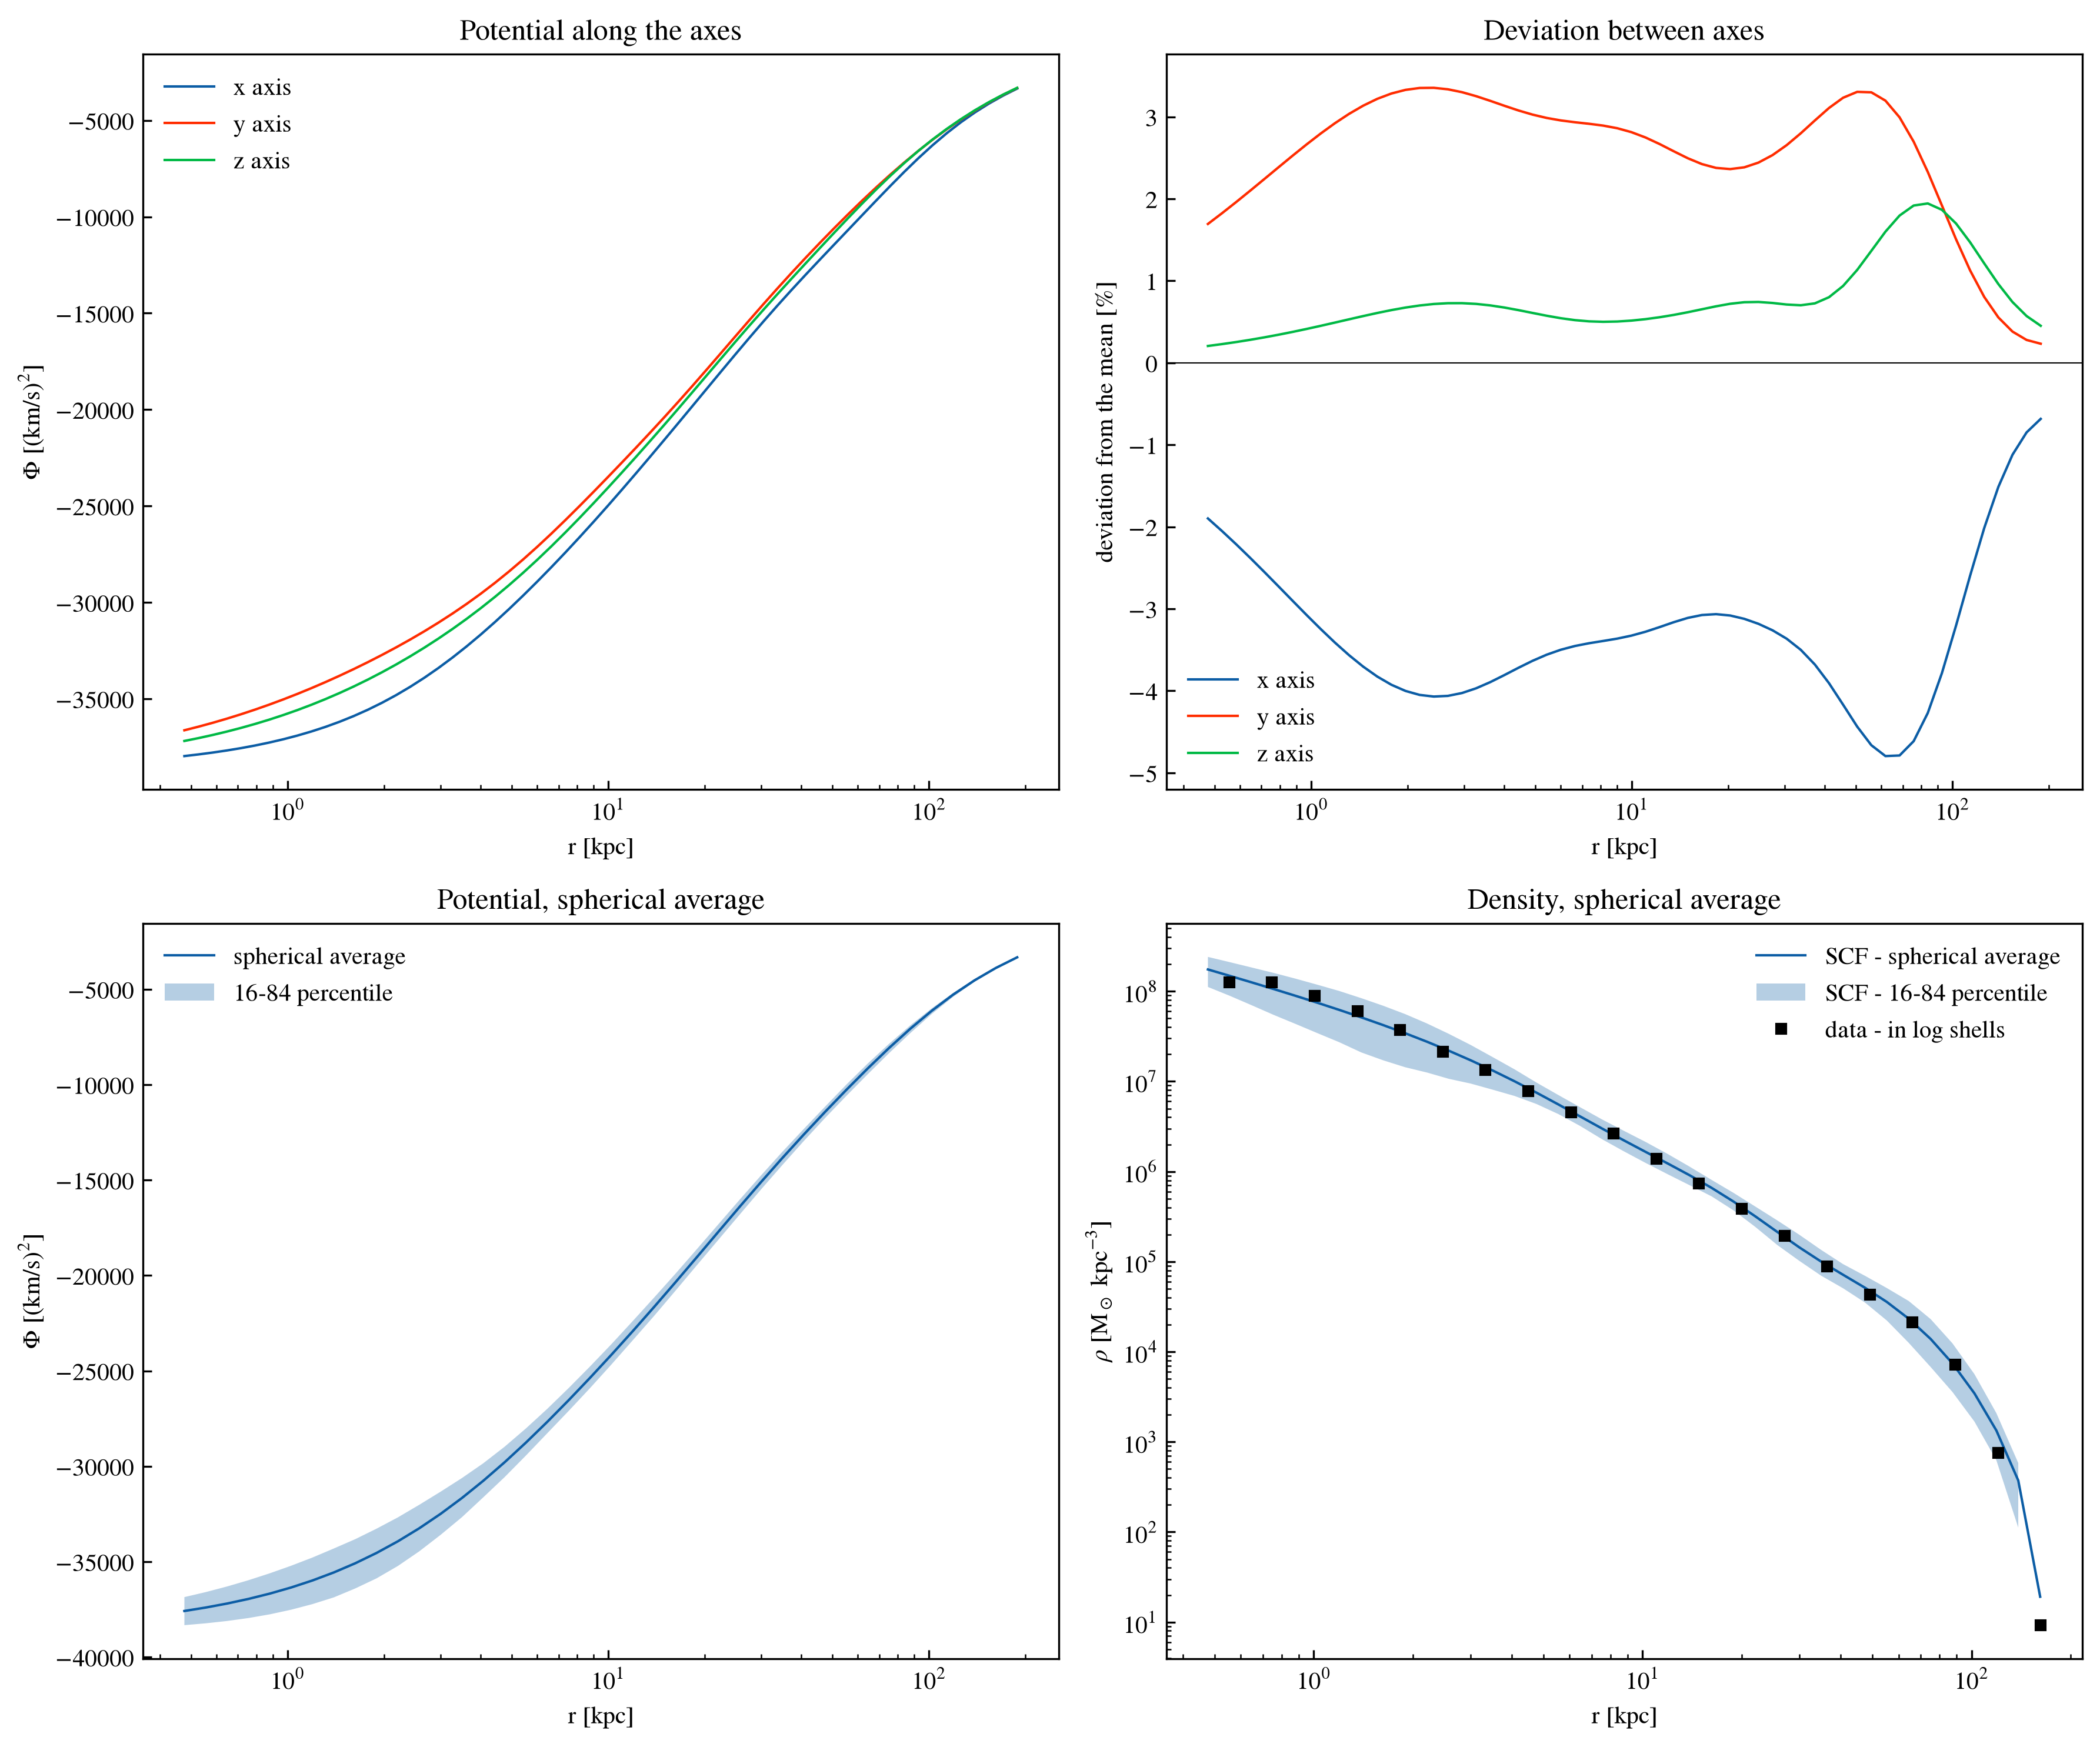

In [9]:
pot_scf, _ = a.build_scf(data_path, plot=True, output=f"{OUTPUT}/halo_potential_density_scf.png");

In the upper plots above the assumption of spherical symmetry can be checked. The potential is plotted along three different directions and compared. A noticeable anisotropy is immediately observed. In the lower plots the potential and density built from the particle data can be seen averaged over the angular coordinates so a graph is obtained that can be compared to the spherically symmetric case. The spread of this is represented by the blue area around the curve, it represents the central 68% (the difference between the 84th and 16th percentile of the data) of the potential/density over all directions. If this spread/distribution is Gaussian this corresponds to the 1 $\sigma$ level. We opted for this kind of spread because it's not certain this underlying spread is Gaussian.

The actual potential was built by galpy's SCFPotential, this is a basis expansion and using it requires an assumption or choice as to how many terms should be kept. To check our choice was correct the density was calculated and compared to the density calculated based on the model. This seemed like a more efficient idea than fitting a whole host of models.

In the figure below the (no longer averaged) density and potential of the model are shown, it's again clear that the assumption of spherical symmetry is rather faulty.

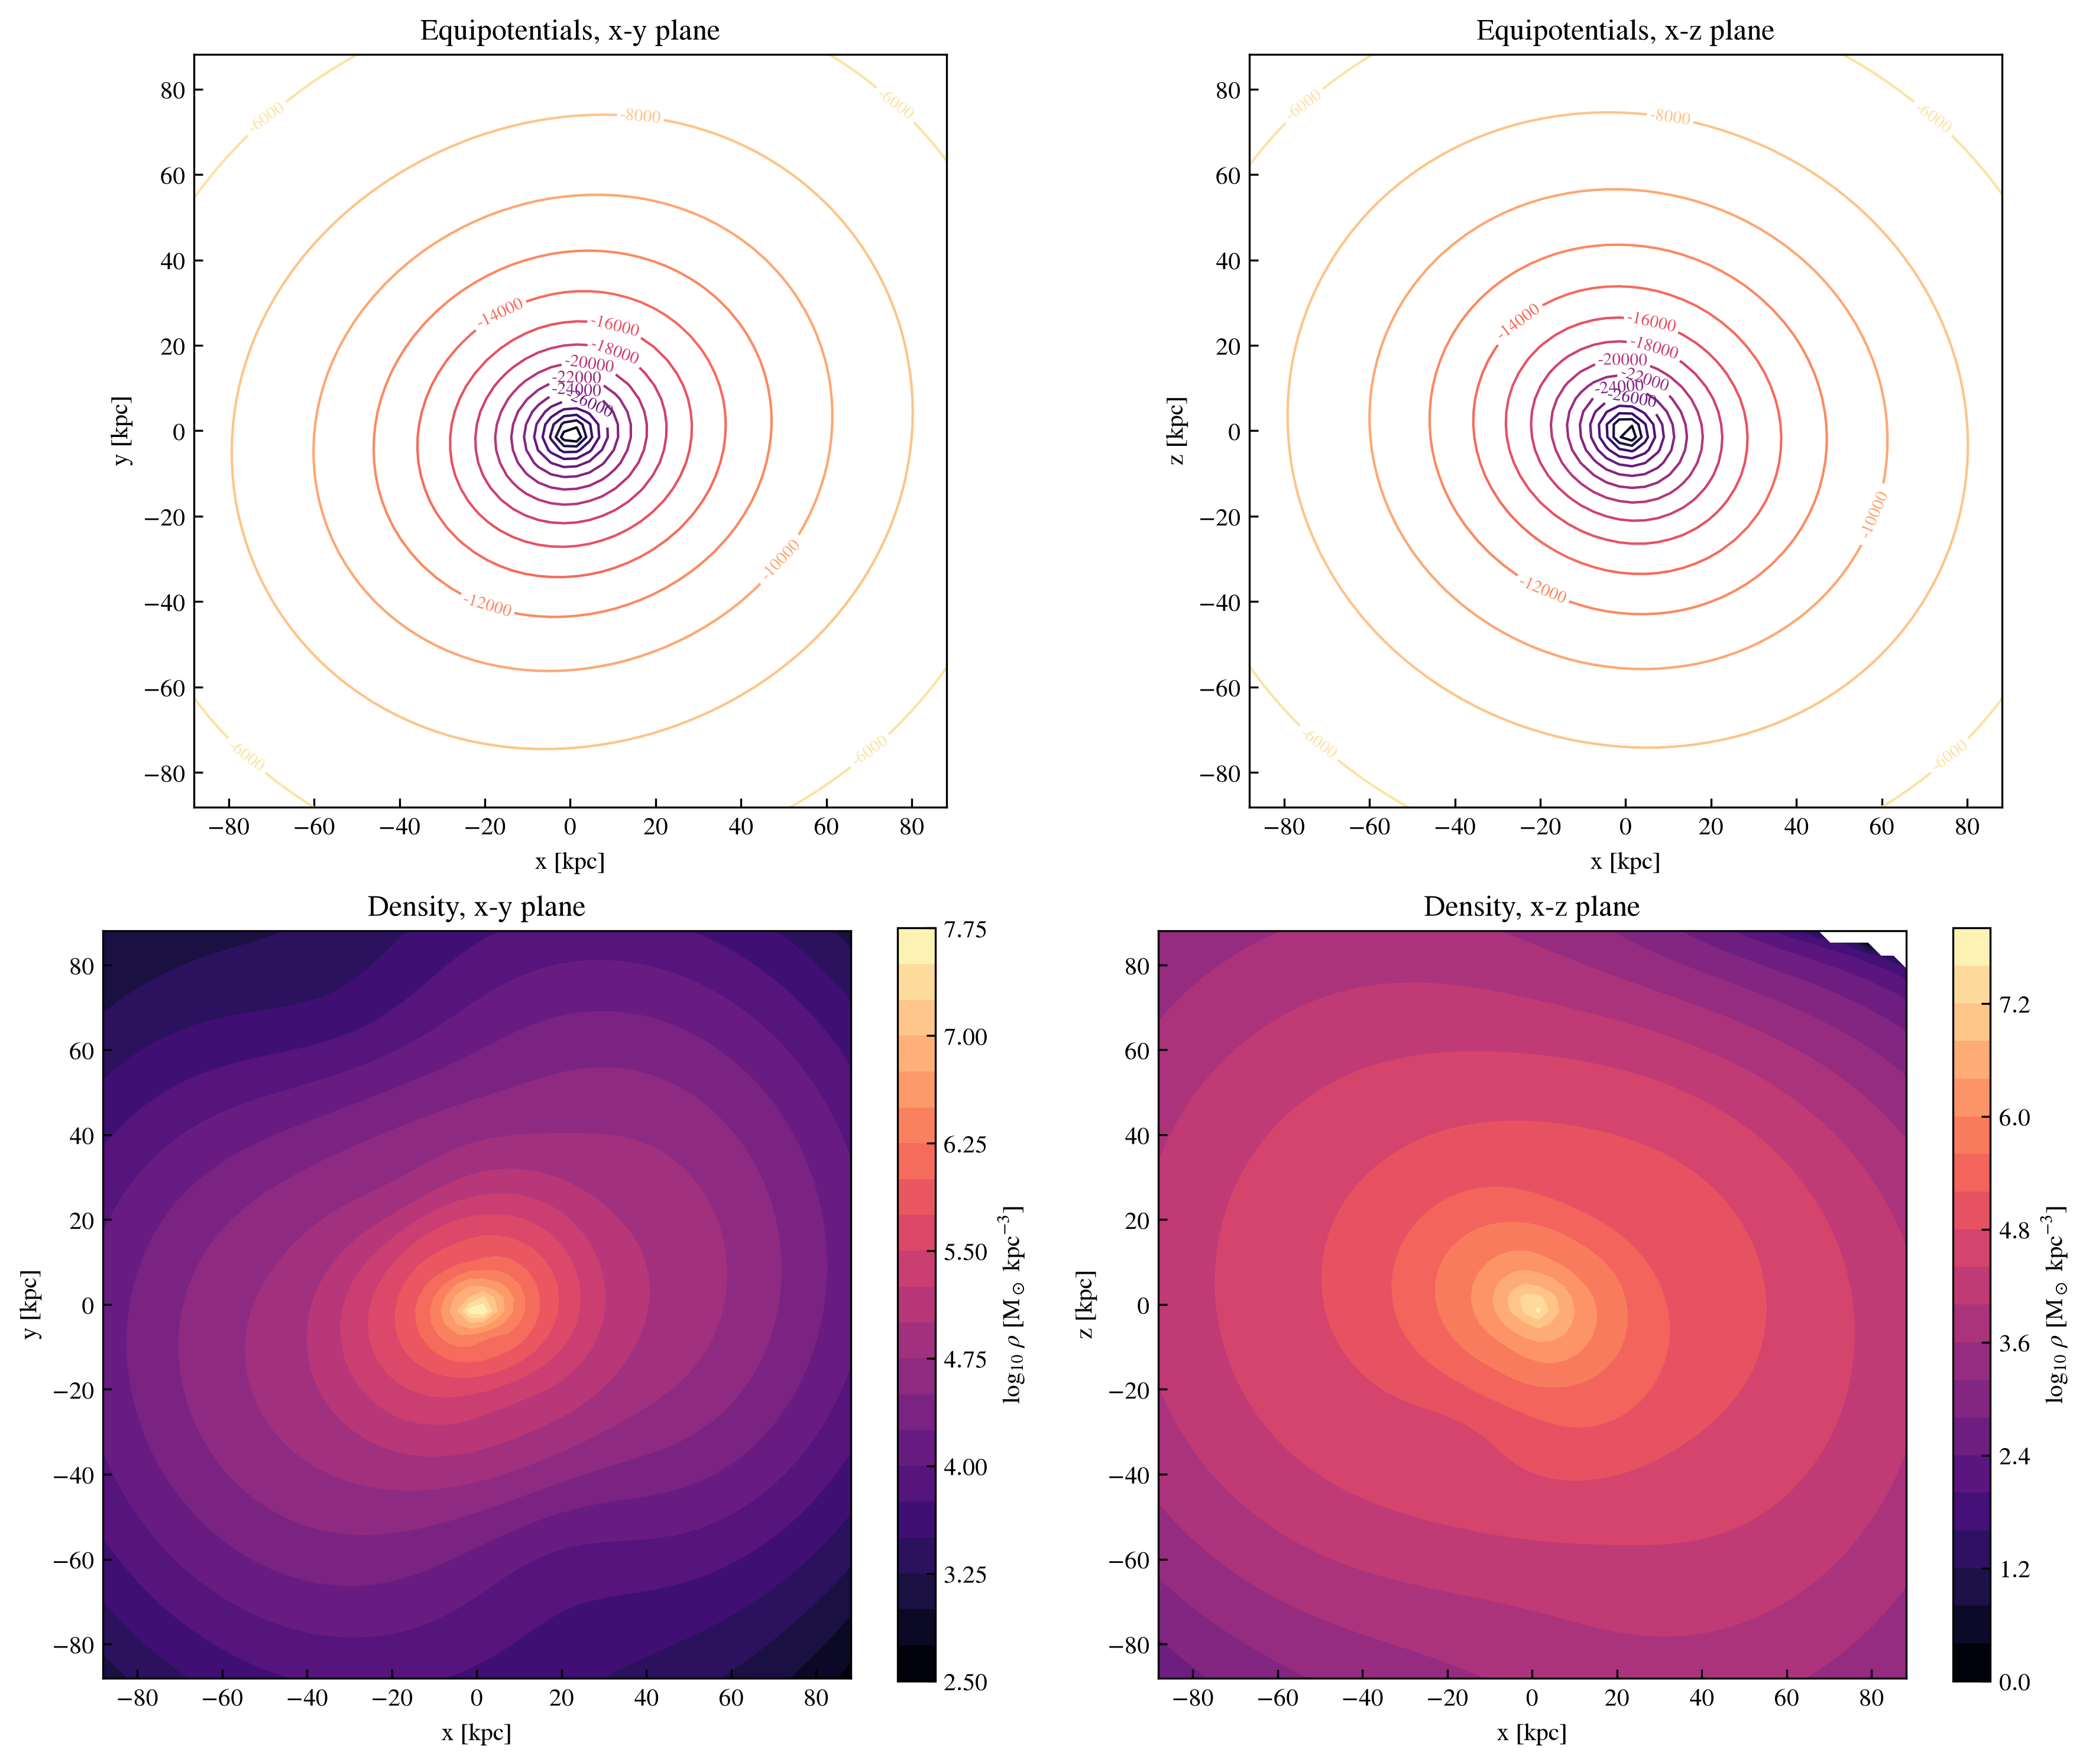

In [10]:
a.plot_potential_density_scf_2d(pot_scf, data_path, plot=True, output=f"{OUTPUT}/halo_potential_density_scf_2d.png");

#### Orbits

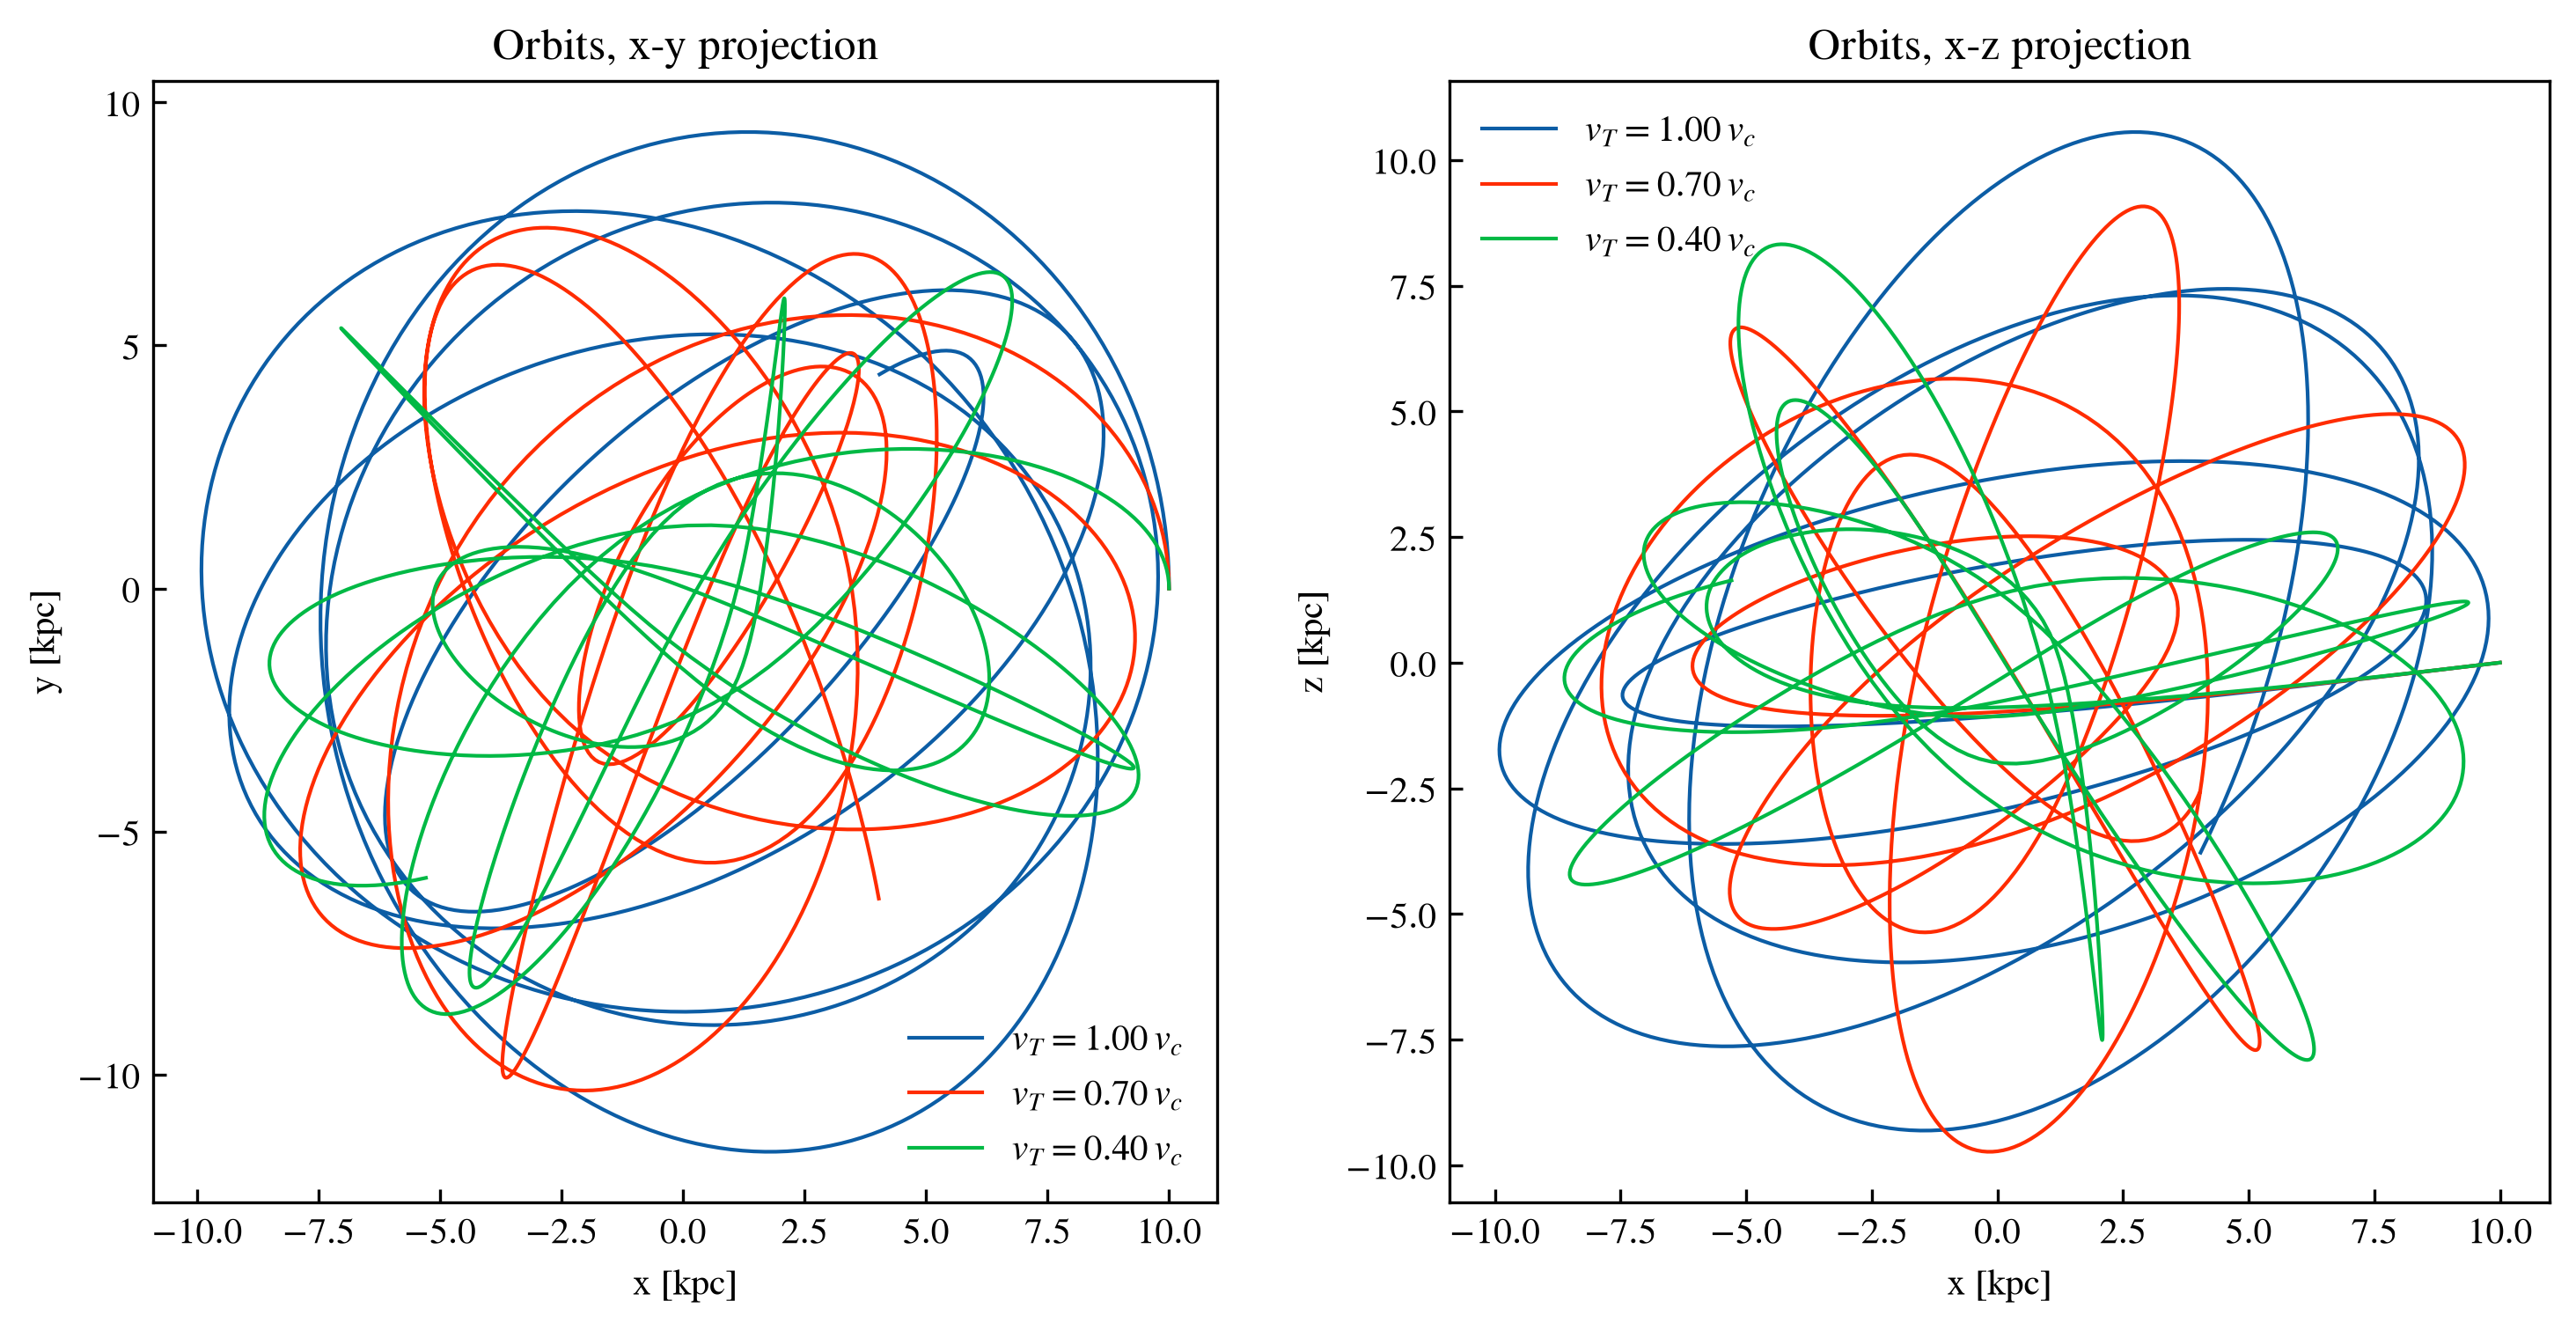

In [10]:
a.integrate_orbits_scf(pot_scf, r0=10 * u.kpc, plot=True, output=f"{OUTPUT}/dm_orbits_scf.png");

#### Dynamical Analysis

Here the rotation curve calculated in the three distinct ways can be seen again. Now it can be confirmed that the discrepancy between the Einasto and the enclosed mass circular velocity was indeed due to the faulty assumption of spherical symmetry. Again, the discrepancy between the tangential velocity and the other curves remains for the same reasons mentioned previously.

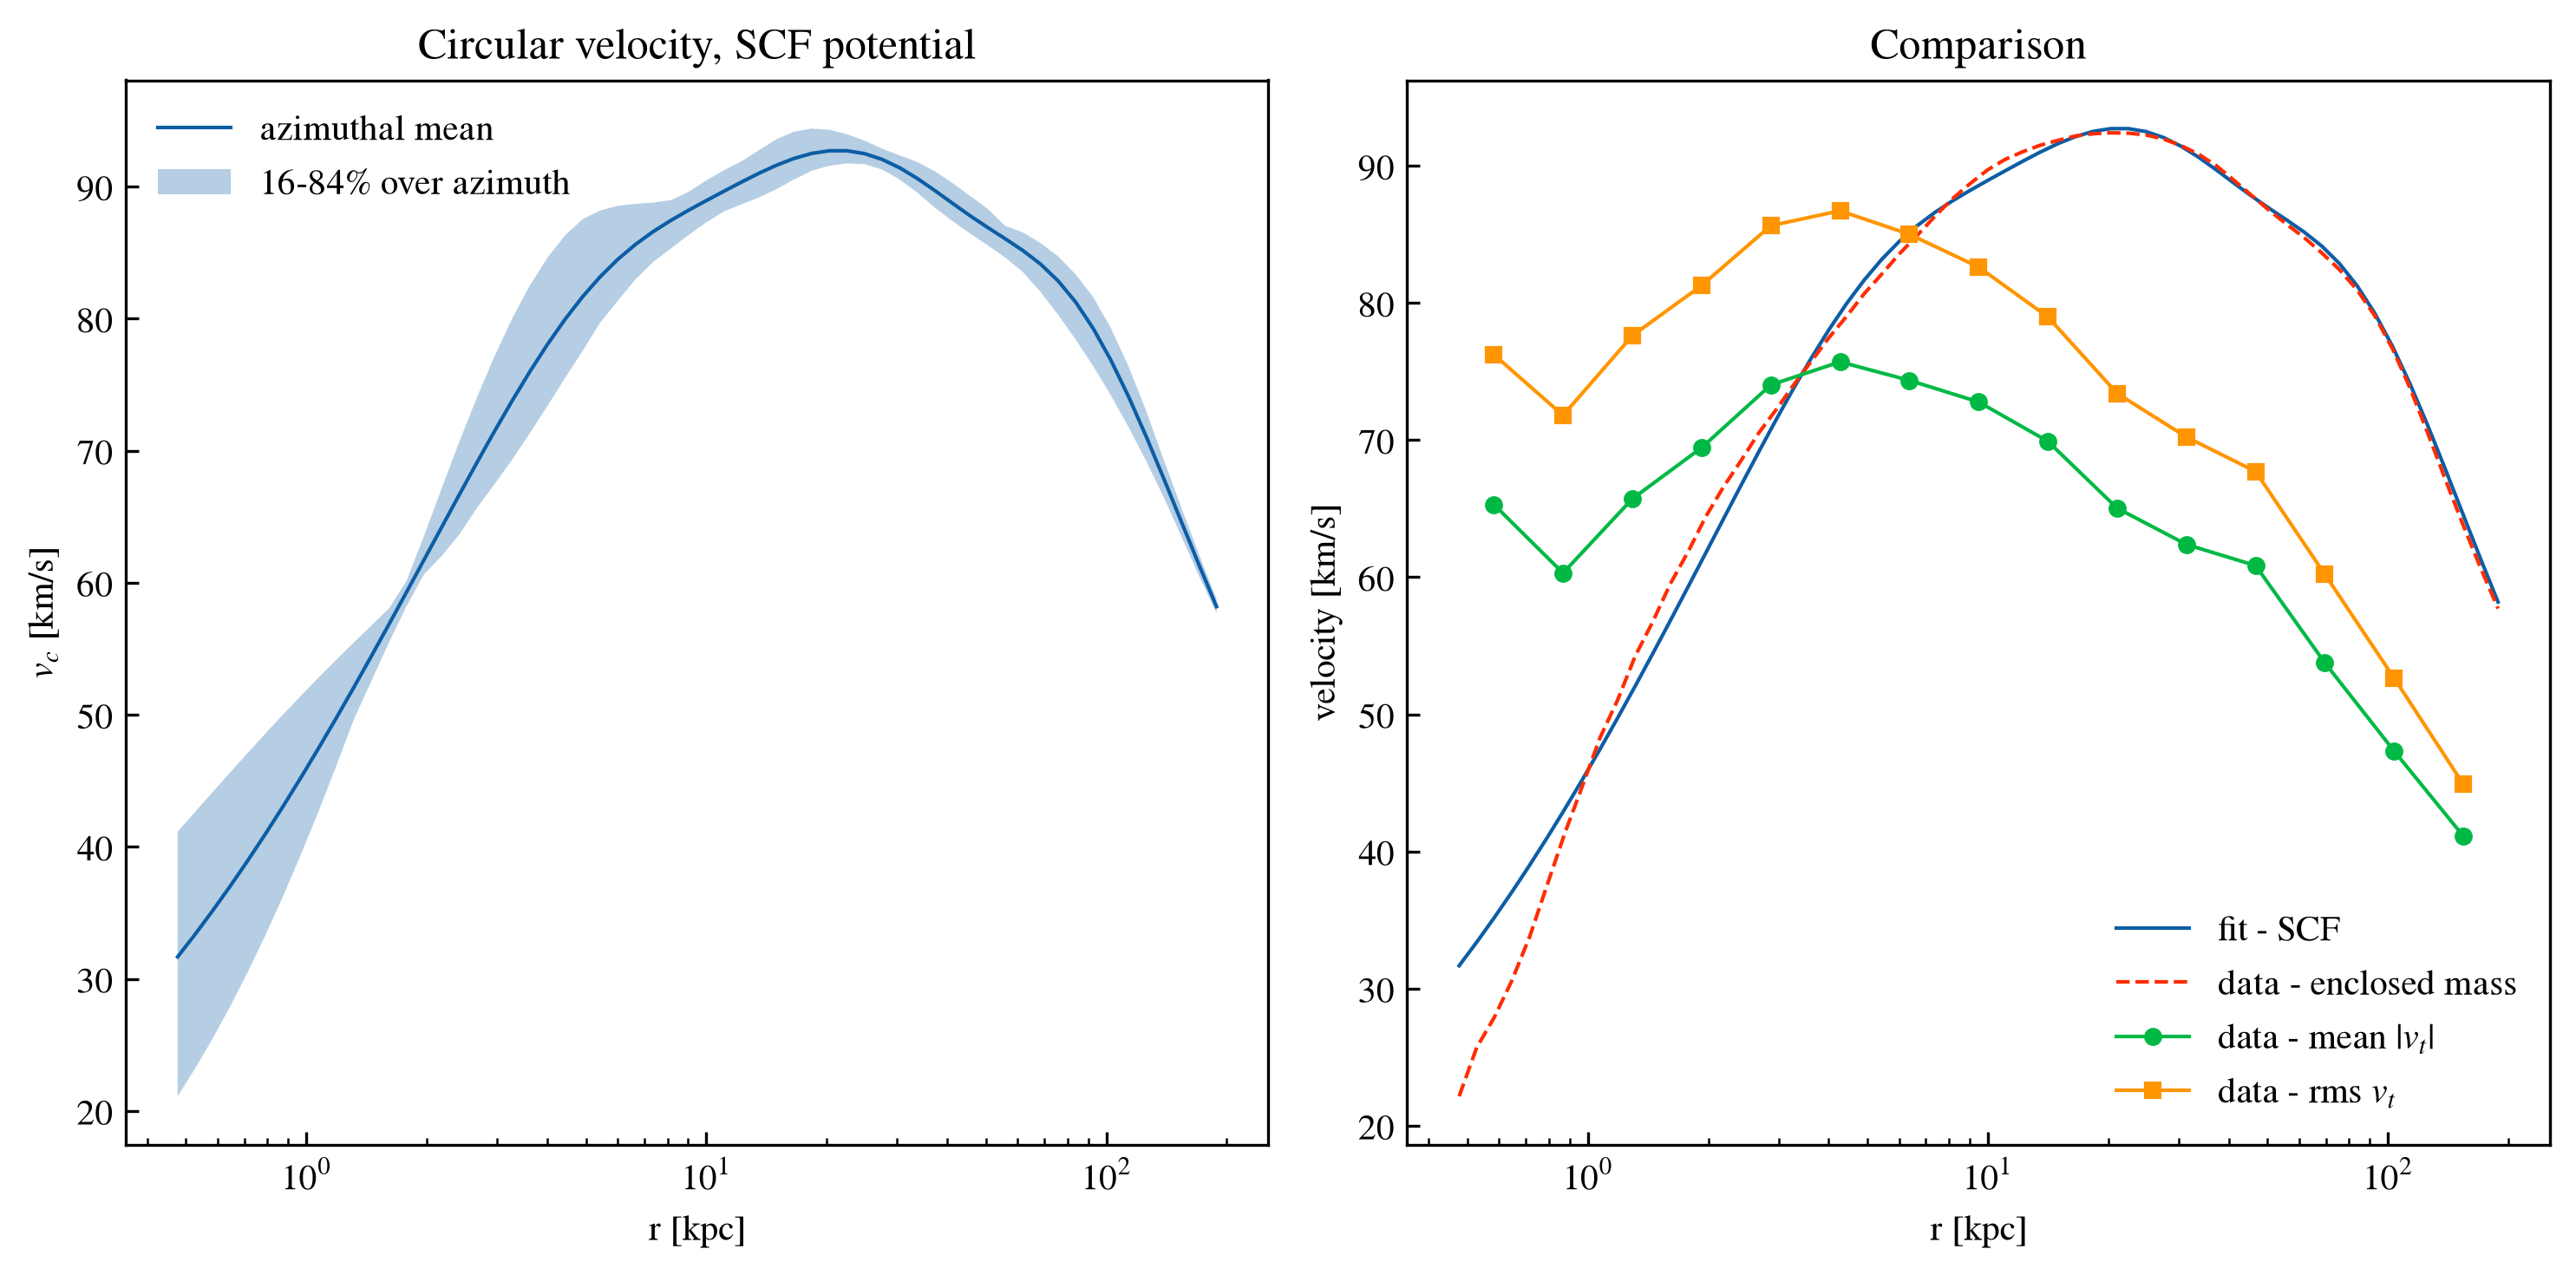

In [11]:
a.compare_rotation_curves_scf(data_path, plot=True, output=f"{OUTPUT}/dm_circular_velocities_scf.png");

## B: Large Scale Statistics

In [2]:
data_path = "data/TNG50-1-Dark_subhalosCat.hdf5"
min_mass = 5e8 # minimum subhalo mass in Msun, used for corr func
box_size, positions, masses = b.get_subhalo_data(data_path, min_mass=0.0) # keep all data
print(f"Box size: {box_size:.2f} cMpc, {len(masses)} subhalos after selection")

Box size: 51.67 cMpc, 6616159 subhalos after selection


### Visualization

In the figure below, the column densities along the 3 major axes are plotted to visualize the data. One can see large clumps forming in certain areas, while others are very empty. This will affect the choice of algorithm for calculating autocorrelation functions.

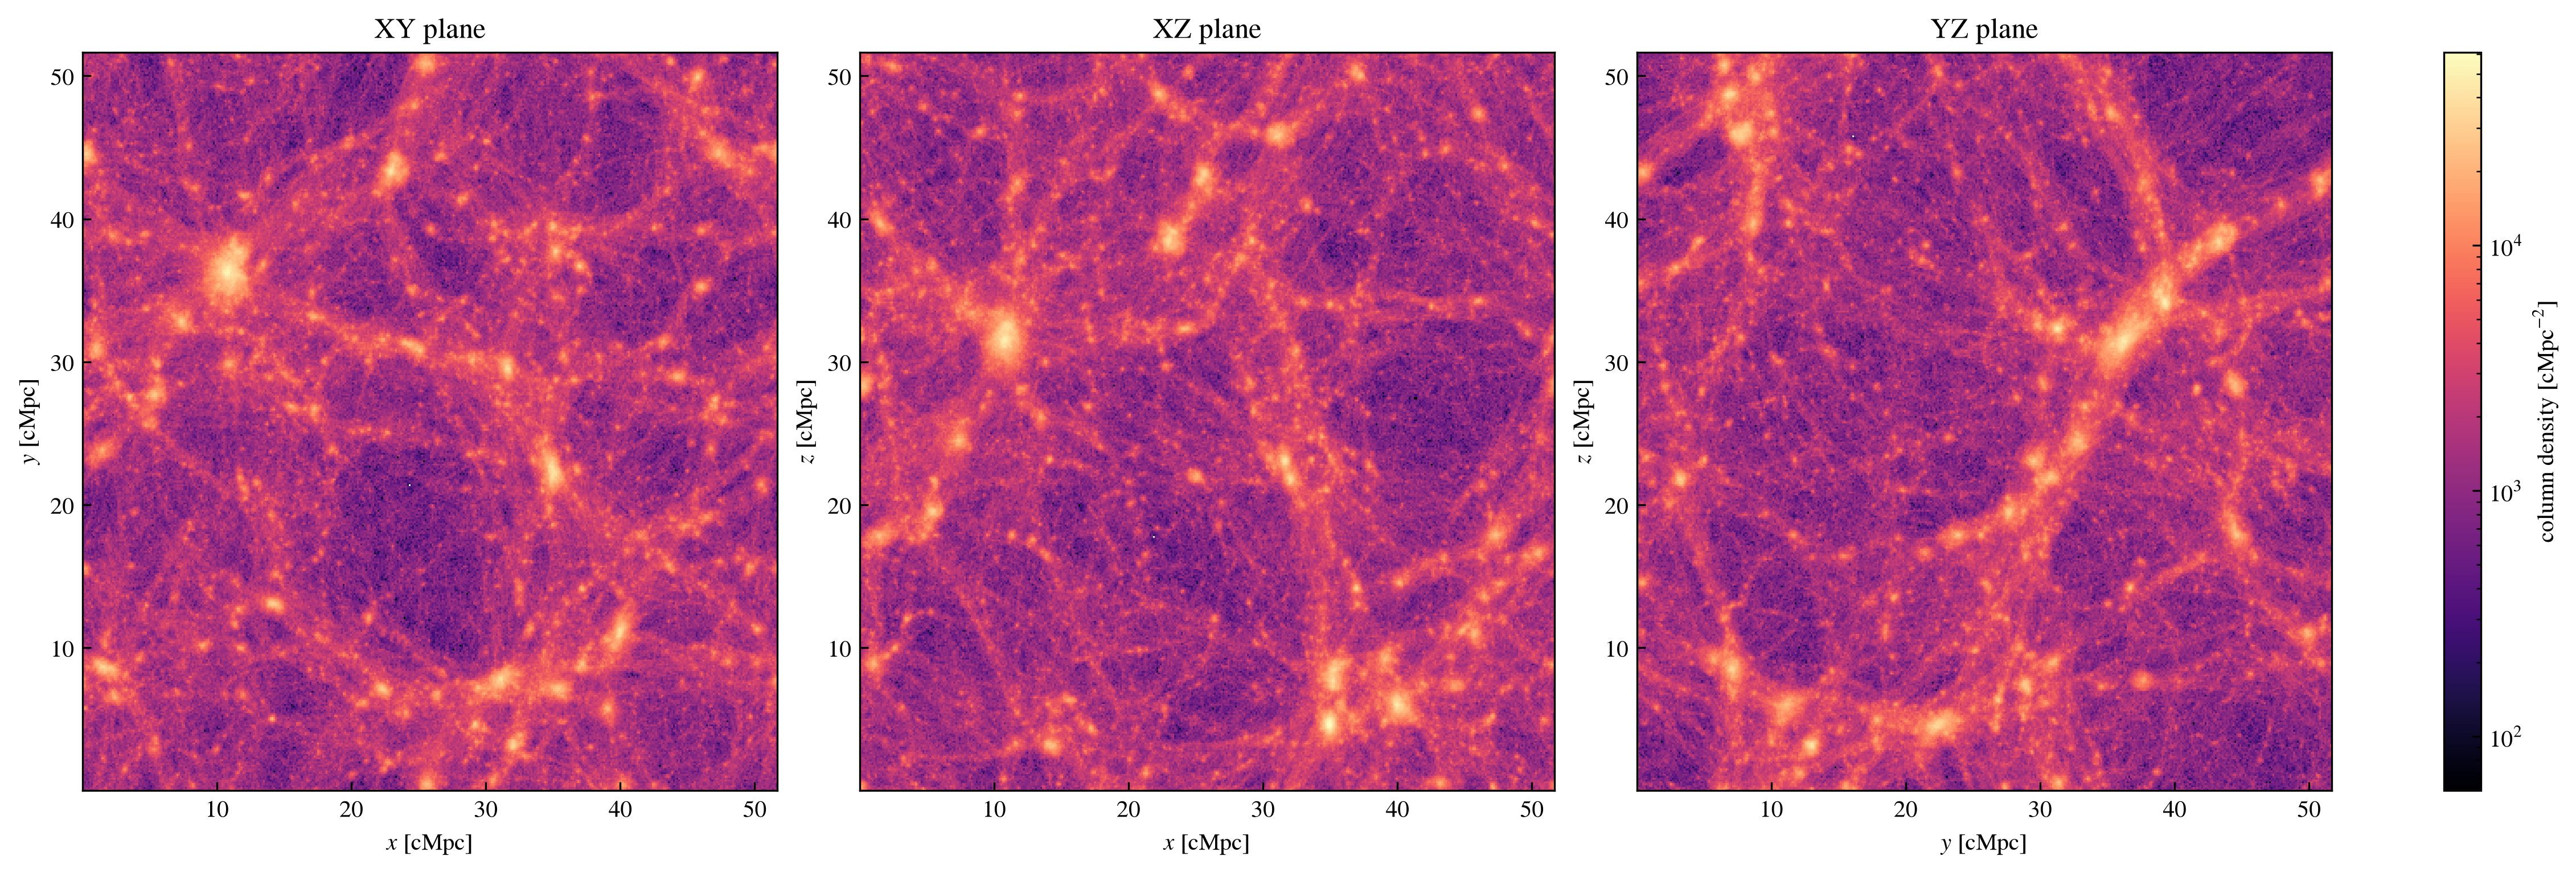

In [15]:
b.plot_column_density(positions, n_bins=400, output=f"{OUTPUT}/subhalo_column_density.png");

### Mass Function

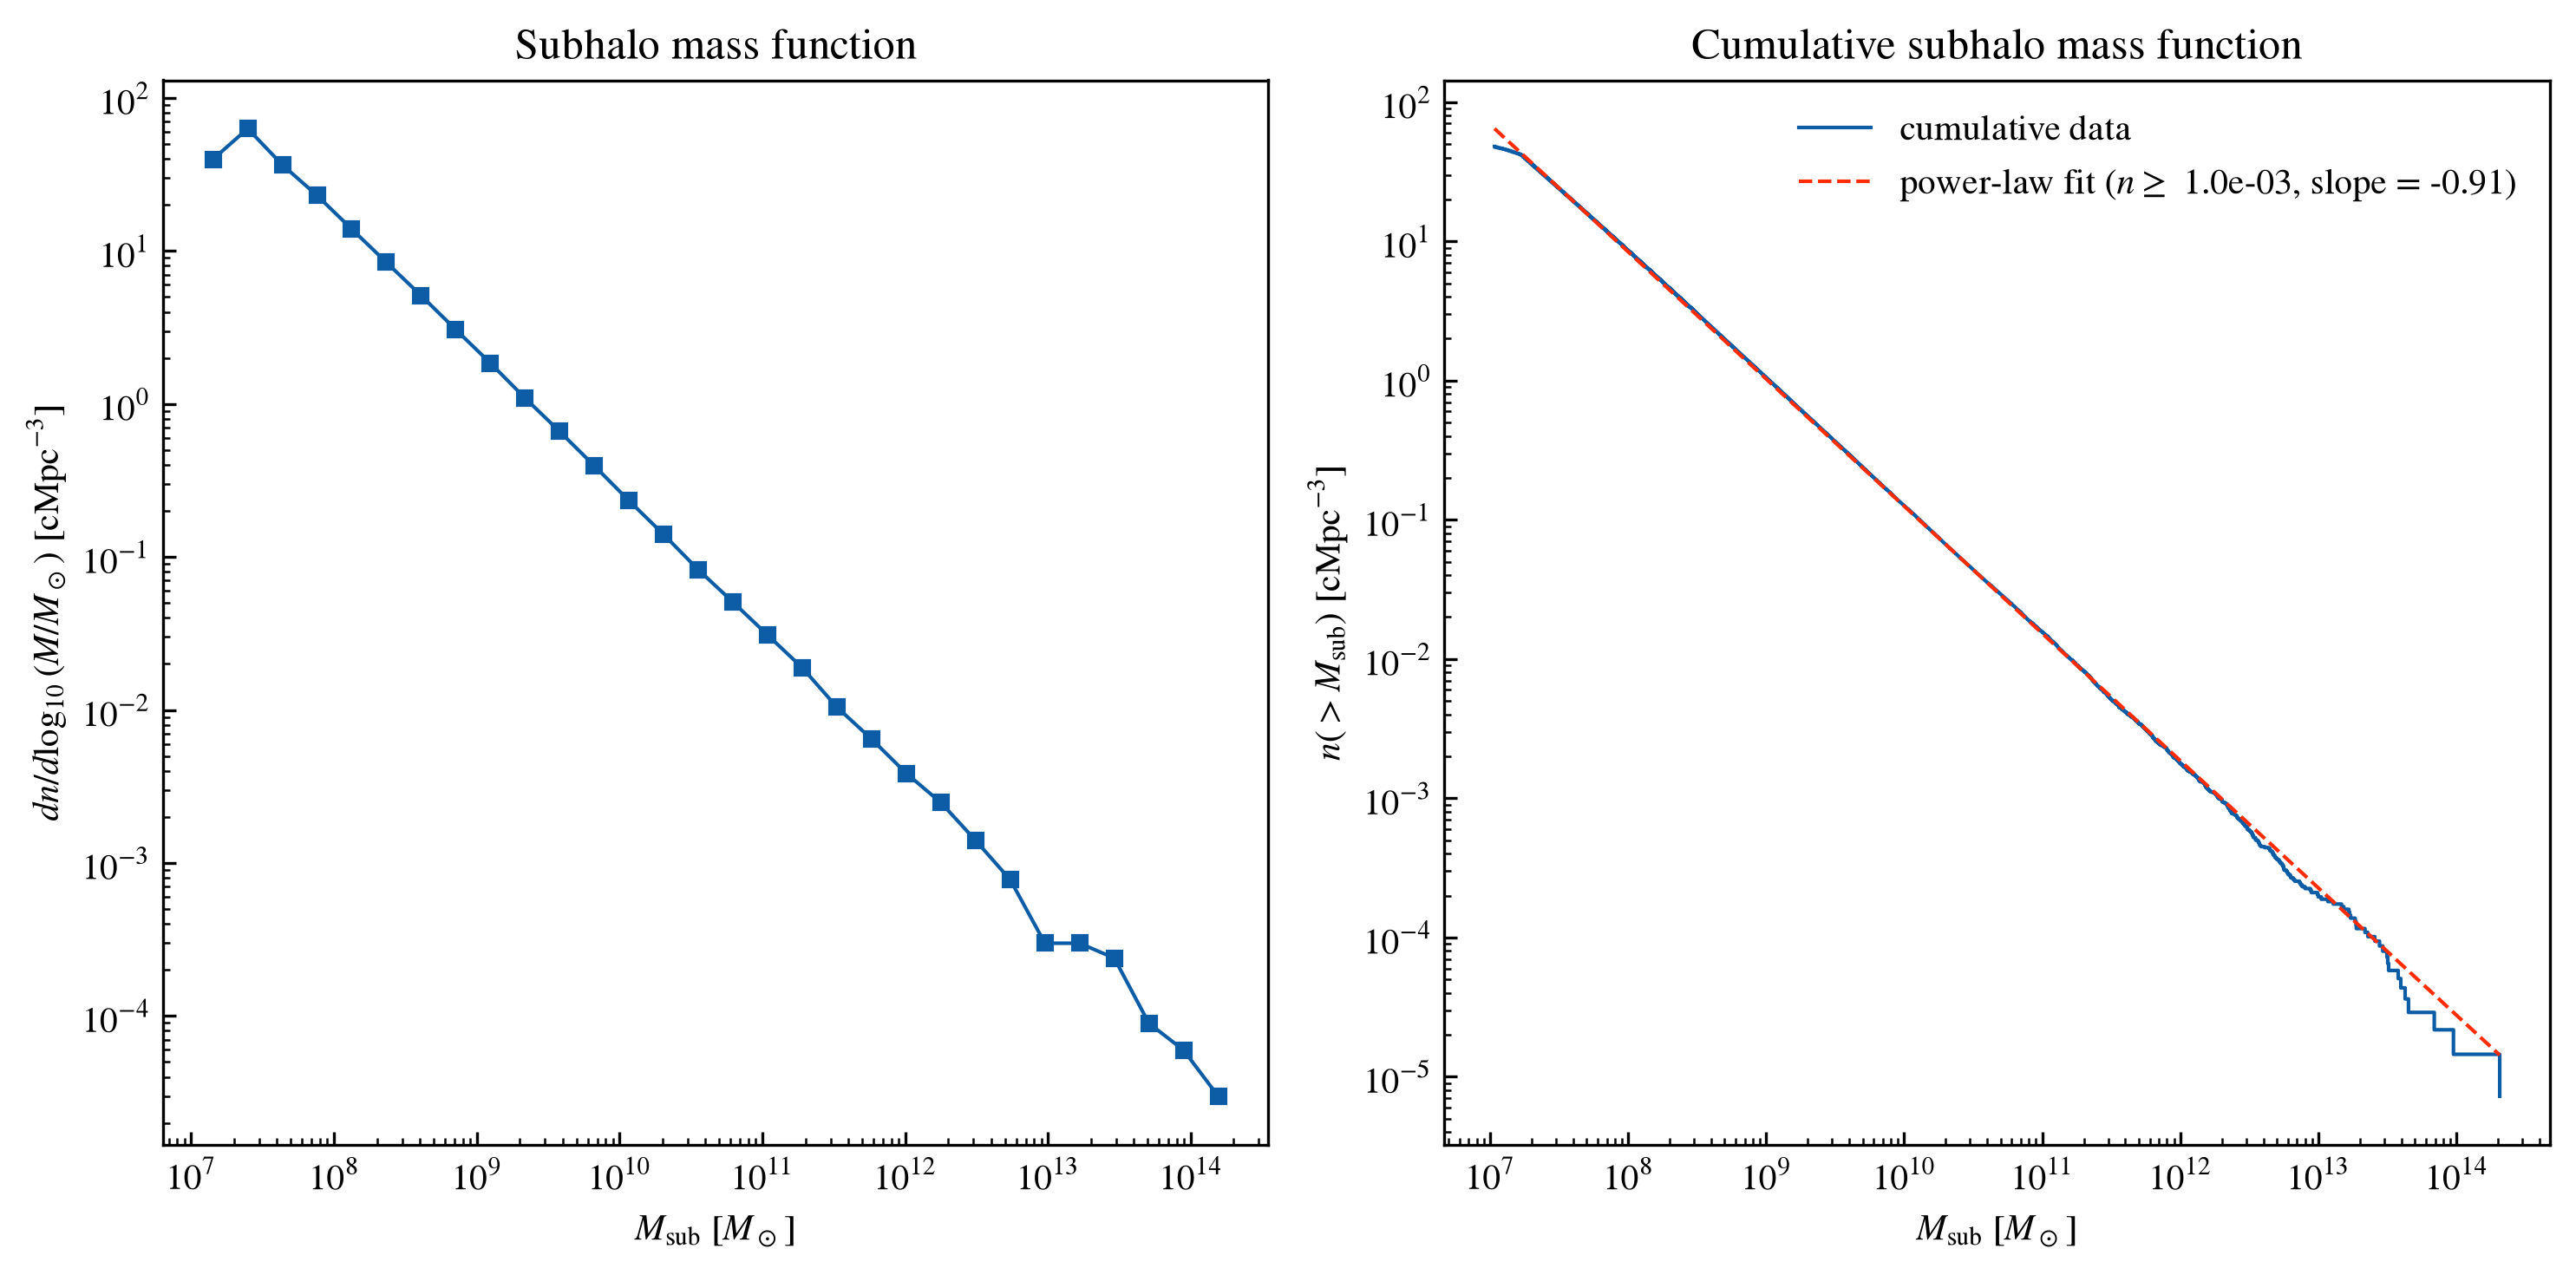

In [16]:
b.plot_mass_function(masses, box_size, output=f"{OUTPUT}/subhalo_mass_function.png");

The mass function (left) and cumulative mass function (right) are shown above (per unit of volume). One can observe a clear power law where the number of halos decreases with mass. To obtain the exponent of the power law, a linear fit was performed for the cumulative mass function. The reason for using the cumulative function is that this is exact, while for the differential function logarithmic binning must be used. We find an exponent of -0.91 for the cumulative function, which translates to -1.91 for the differential function. Note that the fit was performed for $n \geq 10^{-3}$ to exclude noisy data. This relation agrees with the literature (see e.g. [Springel et al.](https://arxiv.org/abs/0809.0898))

### Autocorrelation Function

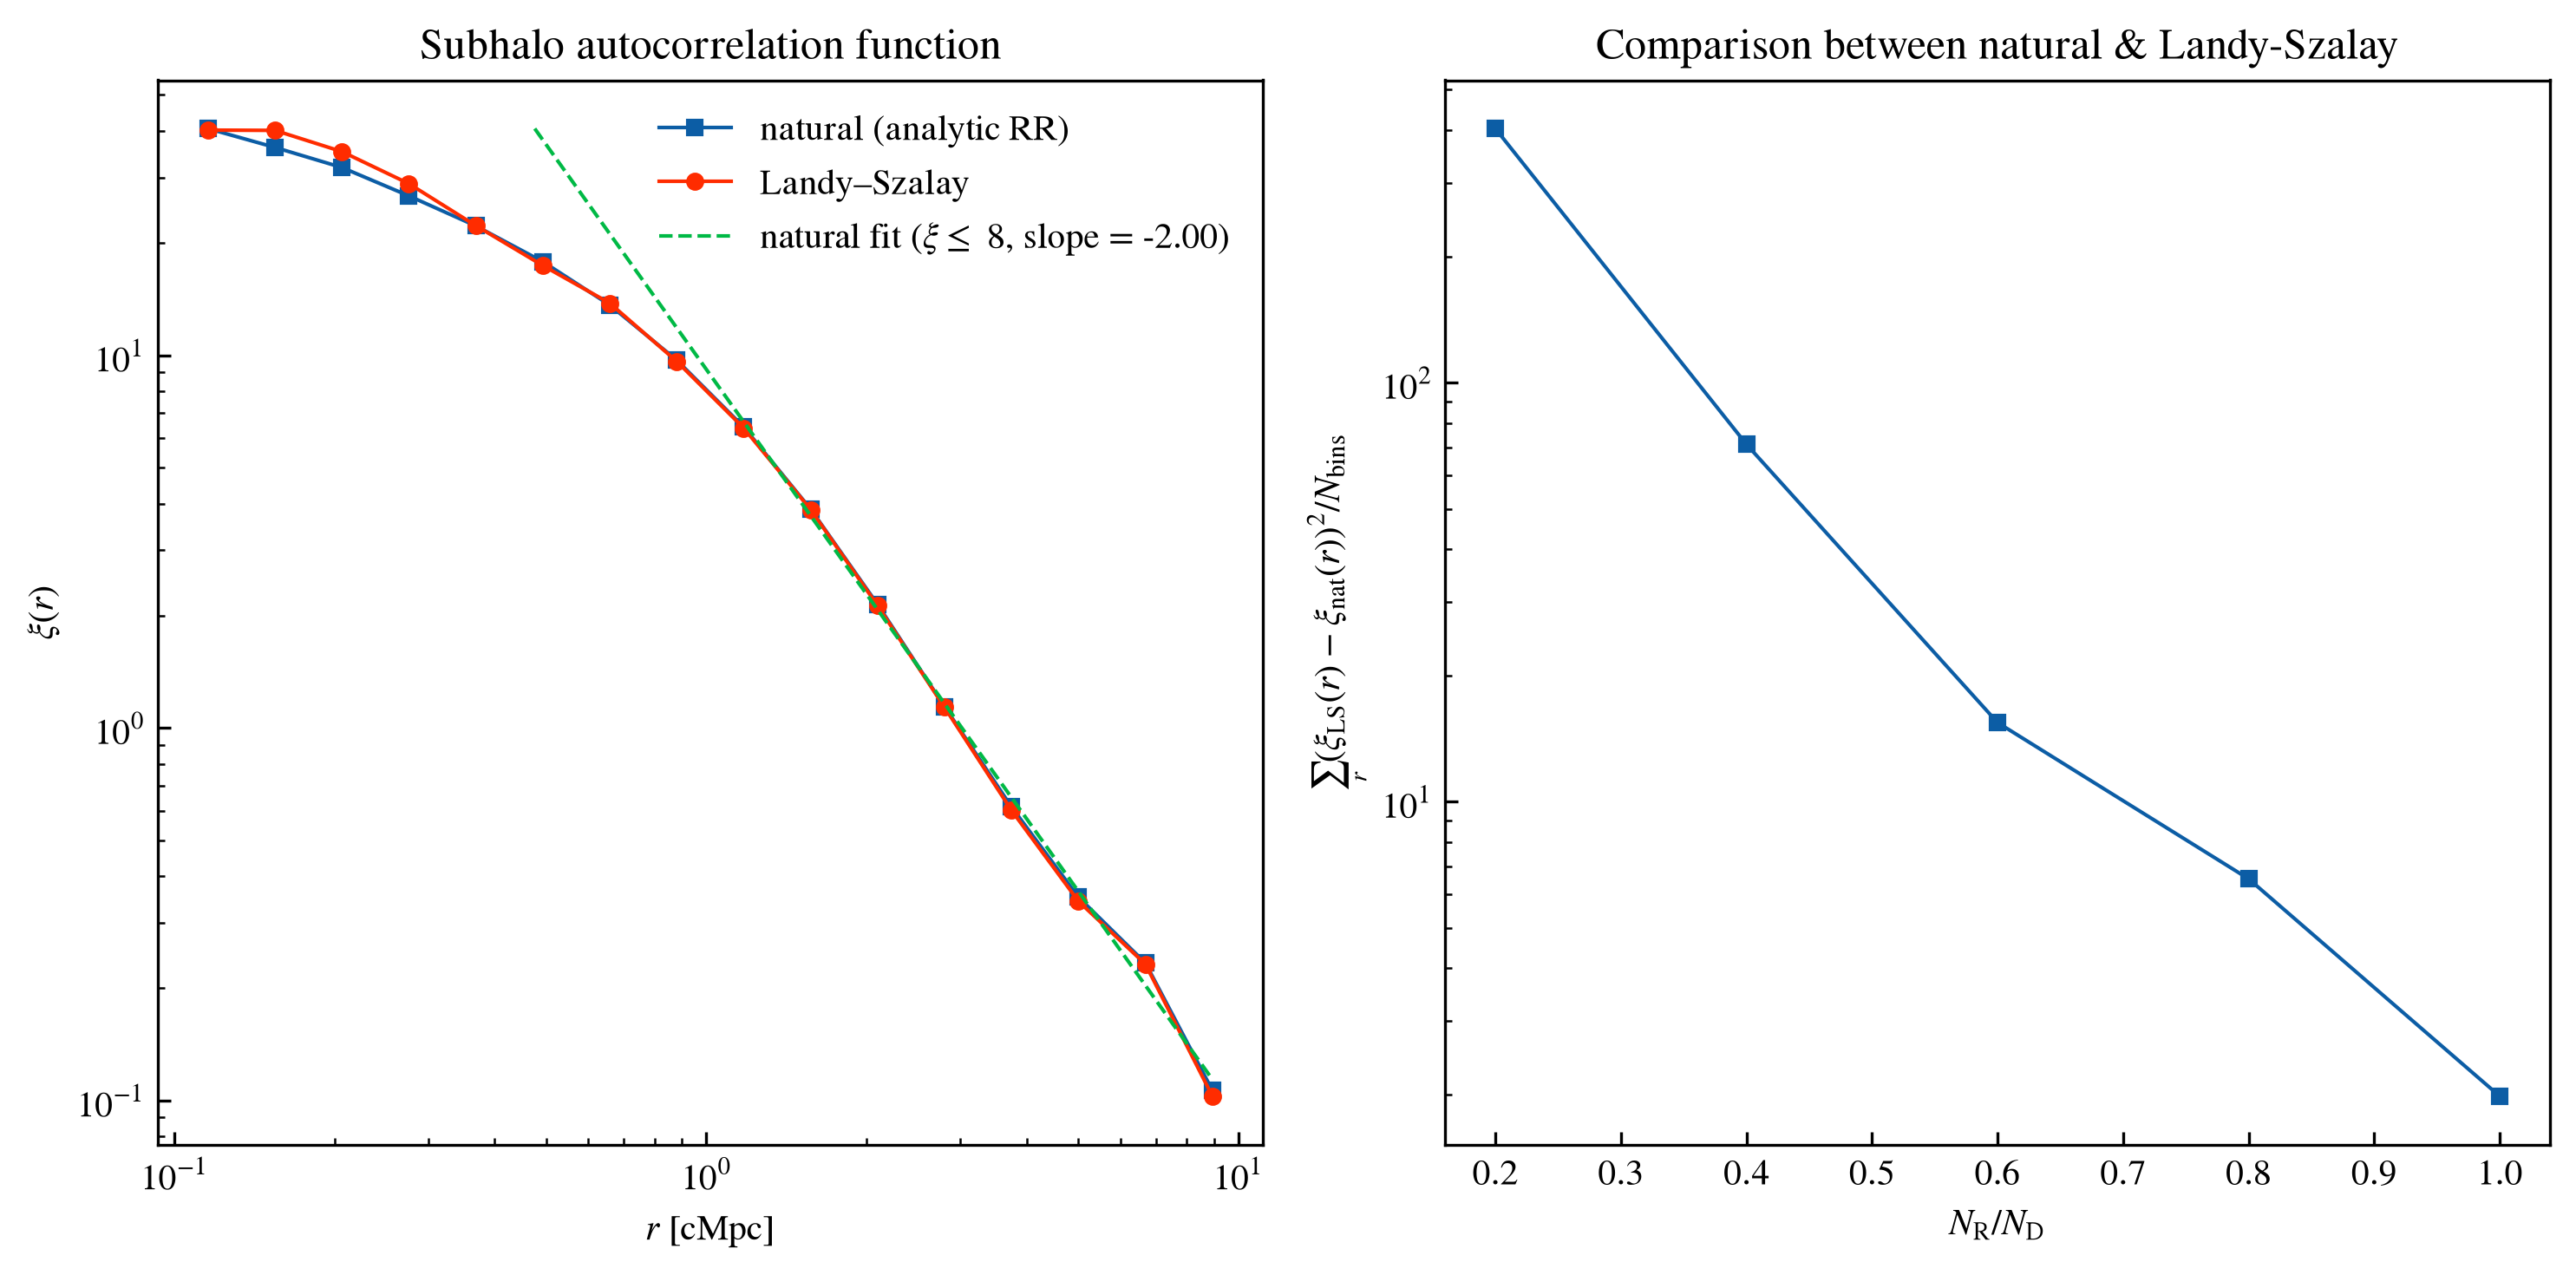

In [ ]:
positions_sample = b.sample_positions(positions, max_halos=100000)
b.plot_correlation_function_comparison(positions_sample, box_size, output=f"{OUTPUT}/subhalo_correlation_function_comparison.png");

The natural and Landy-Szalay (LS) estimators for the autocorrelation function are defined as:

$$\chi_\mathrm{nat}(r) = \frac{\mathrm{DD}(r)}{\mathrm{RR}(r)} - 1 \quad\quad \chi_\mathrm{LS}(r) = \frac{\mathrm{DD}(r) - 2\mathrm{DR}(r)}{\mathrm{RR}(r)} + 1$$

where $\mathrm{AB}(r)$ is the number of pairs within a distance $[r/w, wr]$ (log bins) between catalogues $\mathrm{A}$ and $\mathrm{B}$ (normalized by the total number of pairs). In practice, $\mathrm{D}$ is (a uniformly selected subset of) the TNG50 subhalo catalogue, and $\mathrm{R}$ is a random catalogue. An analytical expression for $\mathrm{RR}(r)$ can be obtained by considering spherical shells between two radii $r/w, wr$. Then, the number of particles within a shell is given by the density x volume fraction of that shell, and the number of pairs is:

$$\mathrm{RR}(r) = \frac{N(N - 1)}{2} \frac{4\pi r^3}{3L^3}(w^3 - \frac{1}{w^3})$$

Since TNG50 is a periodic cosmological volume, this is valid for $r < L/2$ (and indeed $\xi(r)$ only makes sense for this range). Furthermore, $\mathrm{DR}(r) = \mathrm{RR}(r)$ and the LS estimator is reduced to the natural one.

In the figure above, the natural estimator was calculated using the analytical expression, while for the LS estimator a random catalogue was built. Note that, there are $\mathcal{O}(10^6)$ subhalos and thus $\mathcal{O}(10^{12})$ pairs in the full catalogue. To compare the estimators while keeping computation time low, a subset of 100,000 halos was randomly selected from $\mathrm{D}$. Furthermore, the distance was kept below $0.2 L \sim 10$ cMpc, since above this we expect finite size effects to become apparent.

At small distances, there is a discrepancy between the two, since the pair count for the random catalogue at that distance is low. To show that this is noise of random origin, the difference between natural and LS is plotted (right) for increasing size of the random catalogue. Indeed, one observes a systematic decrease.

We now know that the correlation function can be calculated using the natural estimator and the analytic expression for $\mathrm{RR}(r)$, which will keep computation time as low as possible. This was calculated again below, but now for a subset of 500,000 halos (left). Moreover, subsets characterized by a minimal mass were also analyzed to show the difference in definition of what counts as a halo (right).

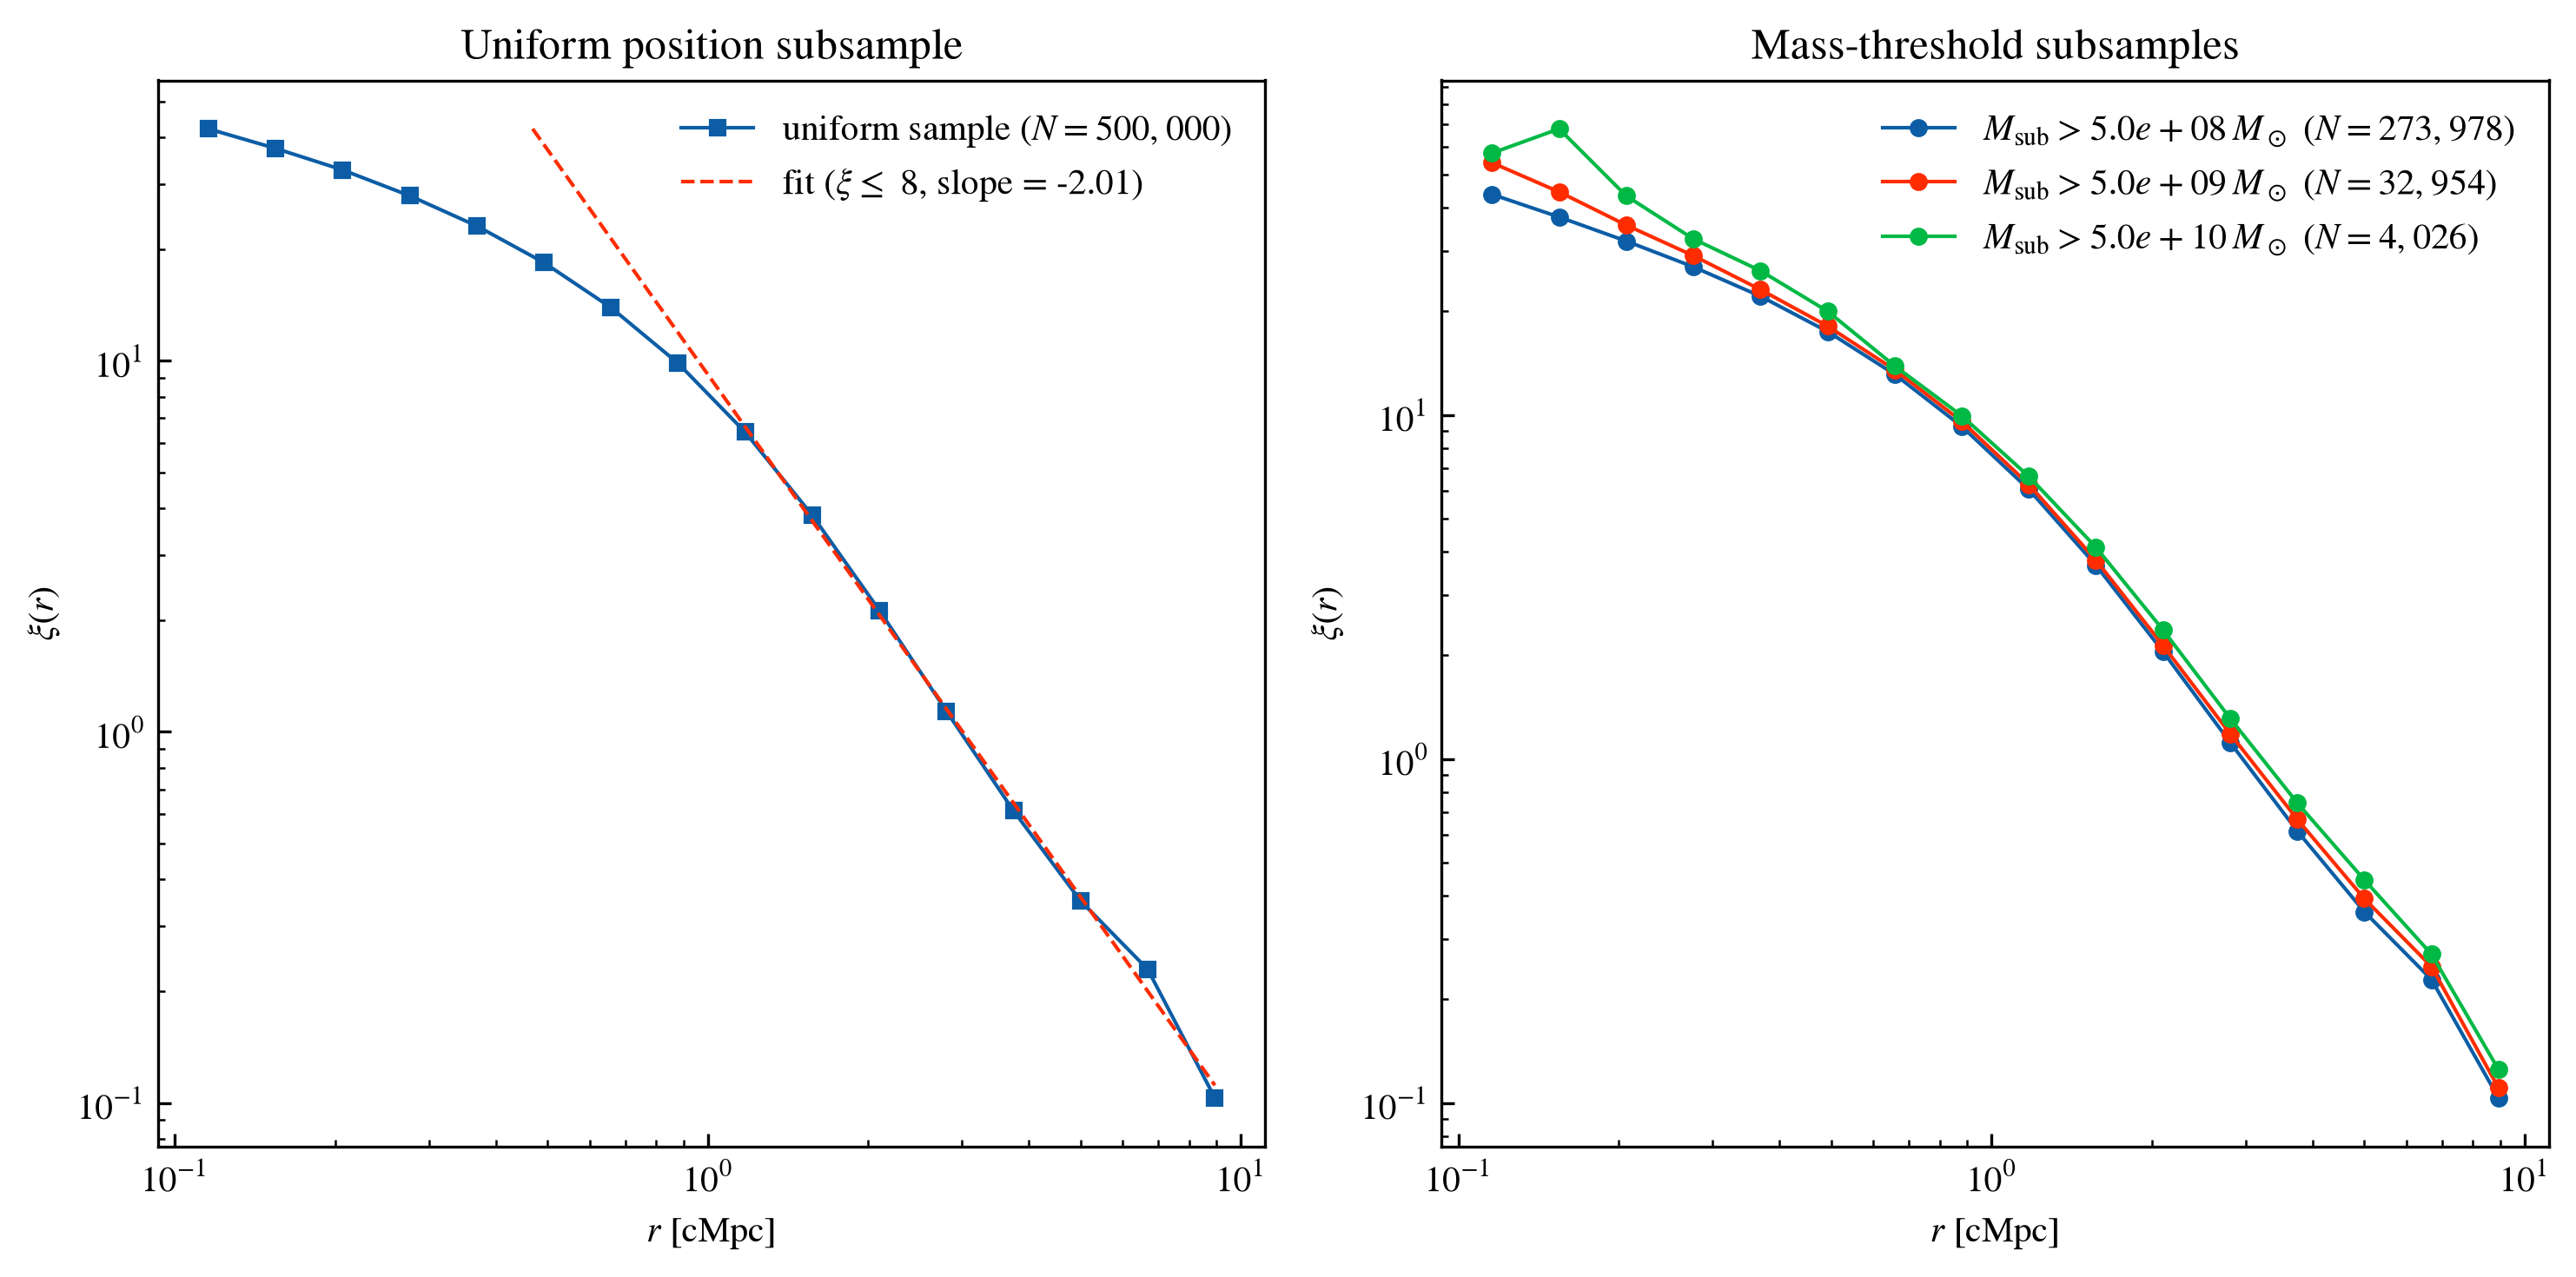

In [3]:
# NOTE: this code cell takes a while due to the size of the simulation, skip once the figure is created
b.plot_correlation_function(
    positions,
    masses,
    box_size,
    n_positions=500000,
    min_masses=(min_mass, 10 * min_mass, 100 * min_mass),
    output=f"{OUTPUT}/subhalo_correlation_function.png",
);

To compute the number of pairs within a distance $[r/w, wr]$, the scipy.spatial object `KDTree` was used. This generates a binary tree by recursively: 1. choosing a direction x, y, z; 2. partitioning the space in two equal halves; until each volume element contains around `leaf_size` (32 or 48) halos. Then, for each halo, it counts the number of halos within a distance $r$ in the following way. If the volume element lies entirely outside a sphere of radius $r$, it discards all those halos. Similarly, if the volume element is contained entirely within the sphere, it adds all the corresponding halos. It is only for volume elements which lie around $r$ for which all halos need to be iterated over and for which the distances need to be calculated.